# `radio-astronomy` 全レコード済み画像 横断検証（Notebook `09` 普遍スワス適用・限界見極め）

前作 [09_patchgan_auto_prior_expanded_inpainting.ipynb](file:///Users/tozastation/ghq/github.com/tozastation/try-astronomy/projects/radio-ml/notebooks/09_patchgan_auto_prior_expanded_inpainting.ipynb) では、**8ch 海岸線ガイド ＋ MPS ネイティブ Spectral-Norm PatchGAN ＋ 実観測データ約 5 倍拡張 ＋ 軌道全自動位置合わせ ＋ Contextual 微細質感転写** により、`METEOR-M2 3_20261026_003009` の 88〜96 px 全欠損ギャップ内部において沿岸勾配保持率 `83.2%`・質感エネルギー `39.5%`・標準 Val PSNR `28.38 dB` を達成しました。

本ノートブックではユーザーの疑問である **「`radio-astronomy`（Garage S3 / `results/`）に蓄積されている『他のすべてのレコード済み衛星画像』へ適用するとどうなるか？」** を体系的に検証します。

### 検証対象となる全 9 ユニーク復号パス（2026-11-22 時点最新 S3 同期を含む）
1. **`METEOR-M2 3_20261026_003009`**（`792×1568`, `Ch1/2/4`）— これまでの標準ベンチマーク（全生存 28.6% / 大欠損 96px）
2. **`METEOR-M2 3_20261027_000649`**（`360×1568`, `Ch1/2/4`）— 第 2 の主要長大パス（全生存 18.5% / 全欠損 57.4%）
3. **`METEOR-M2_GOLDEN_1791698496`**（`1456×1568`, `Ch1/2` のみ）— 今回初めて**全域 `1456×1568` フル復元 ＋ 欠落 `Ch4`（熱赤外）のモデル合成**を実施（なお `GOLDEN_1791698618` はバイナリ完全一致の重複パスのため代表 1 件で代表検証）
4. **`METEOR-M2 3_20261103_004421`**（`96×1568`, `Ch1/2/4`）— 全 Ch 生存 41.4% ＋ 一部 Ch のみ生存 **50.1%** の高救済率パス
5. **`METEOR-M2 3_20261025_005344`**（`40×1568`, `Ch1/2/4`）— 初期成功パス（一部 Ch のみ 55.7%、短尺スワス `H < 64`）
6. **`METEOR-M2 4_20261025_181705`**（`32×1568`, `Ch1/2/4`）— **`METEOR-M2 4` 機の実測パス**（全 Ch 生存 77.9% / 全欠損 **0.0%**）
7. **`METEOR-M2 3_20261122_000222`**（`168×1568`, `Ch1/2/4`）— **本日早朝（`2026-11-22 09:02 JST`）受信の完全未知最新パス**（生存率 2〜8% の極限欠損ストレステスト）
8. **`METEOR-M2 3_20261031_001351`**（`16×1568`, `Ch1/4` のみ）— 近赤外 `MSU-MR-2` ファイル自体が欠落した未知極短スワス
9. **`METEOR-M2 3_20261121_002540`**（`16×1568`, `Ch2/4` のみ）— 昨日受信の可視光 `MSU-MR-1` ファイル自体が欠落した未知極短スワス

## 1. 理論とデータ準備：汎用スワス適応機構 ＆ 学習済みバンドルの保存・再利用

蓄積された多様な実測パスすべてを単一コードで安全・高速に処理するため、以下の 4 つの普遍化拡張を導入します。

1. **Garage S3 最新同期 ＆ 条件ハッシュ付きモデルキャッシュ（`projects/radio-ml/models/nb09_coastline_patchgan_bundle.pt`）**:
   - `sync_meteor_dataset(METEOR_DIR, refresh=True)` により本日受信の `METEOR-M2 3_20261122_000222` までローカルキャッシュを最新化します。
   - `model_cache.py` により学習条件辞書（モデル構造・ステップ数・学習率・損失重み・データ件数・シード）の SHA-256 `config_hash` を照合し、条件未変更なら `0.2 秒` 未満で即時ロード、条件が変更された場合は自動的に Notebook `09` 同一レシピで再学習してキャッシュを更新します。
2. **欠落バンド対応ユニバーサル読込（`load_any_meteor_pass`）**:
   - `MSU-MR-1 / 2 / 4` のうち存在するファイルのみを真の観測マスク `mask_hw3 = 1.0` として読み込み、`1031`（`Ch2` 欠落）・`1121`（`Ch1` 欠落）・`GOLDEN`（`Ch4` 欠落）では欠落チャネルのマスクを厳密に `0.0` として **ネットワーク自身によるクロスバンド合成** に委ねます。
3. **短尺スワス適応パディング ＆ 動的 Onion-Peel 深度（`restore_universal_c2f`）**:
   - 高さ `H < 64 px` の短尺パス（`16〜40 px`）は垂直端エッジ拡張パディング（`mode="edge"`）で `64 px` へ安全拡張したうえで推論後に元の高さ `H` へ切り出し、`H_pad < 128` の場合は `2×` ダウンサンプリング経路を自動スキップします。
   - 欠損最大距離 $d_{\max}$ に応じて Onion-Peel ステップ数を $N_{\text{steps}} = \text{clip}(\lceil d_{\max}/11 \rceil, 1, 8)$ へ動的調整し、無欠損帯は `Phase 0` のみで即時完了させ、`GOLDEN` の `152 px` 巨大空白帯は 7 段階で内部へ進行します。

PyTorch: 2.9.1 | 使用デバイス: mps


Garage S3 最新同期完了: 計 230 件


=== 検証対象 全 9 ユニーク復号パス一覧 ===
  METEOR-M2 3_20261026_003009    |  792x1568 | Ch=124 | 全= 28.6% | 部分= 22.7% | 無= 48.7% | 最大空白= 96px
  METEOR-M2 3_20261027_000649    |  360x1568 | Ch=124 | 全= 18.5% | 部分= 24.1% | 無= 57.4% | 最大空白= 96px
  METEOR-M2_GOLDEN_1791698496    | 1456x1568 | Ch=12  | 全=  0.0% | 部分= 85.8% | 無= 14.2% | 最大空白=152px
  METEOR-M2 3_20261103_004421    |   96x1568 | Ch=124 | 全= 41.4% | 部分= 50.1% | 無=  8.5% | 最大空白=  0px
  METEOR-M2 3_20261025_005344    |   40x1568 | Ch=124 | 全= 20.0% | 部分= 55.7% | 無= 24.3% | 最大空白=  8px
  METEOR-M2 4_20261025_181705    |   32x1568 | Ch=124 | 全= 77.9% | 部分= 22.1% | 無=  0.0% | 最大空白=  0px
  METEOR-M2 3_20261122_000222    |  168x1568 | Ch=124 | 全=  0.0% | 部分= 11.4% | 無= 88.6% | 最大空白=128px
  METEOR-M2 3_20261031_001351    |   16x1568 | Ch=14  | 全=  0.0% | 部分= 21.1% | 無= 78.9% | 最大空白=  0px
  METEOR-M2 3_20261121_002540    |   16x1568 | Ch=24  | 全=  0.0% | 部分= 49.5% | 無= 50.5% | 最大空白=  0px


[💾 モデルキャッシュ HIT] nb09_coastline_patchgan_bundle.pt (config_hash=46546fee33518457) -> 条件未変更のため学習をスキップし保存済み重みを即時ロードします


保存済み Notebook 09 バンドルをロード完了: nb09_coastline_patchgan_bundle.pt (hash=46546fee33518457 | Val PSNR=28.39 dB)


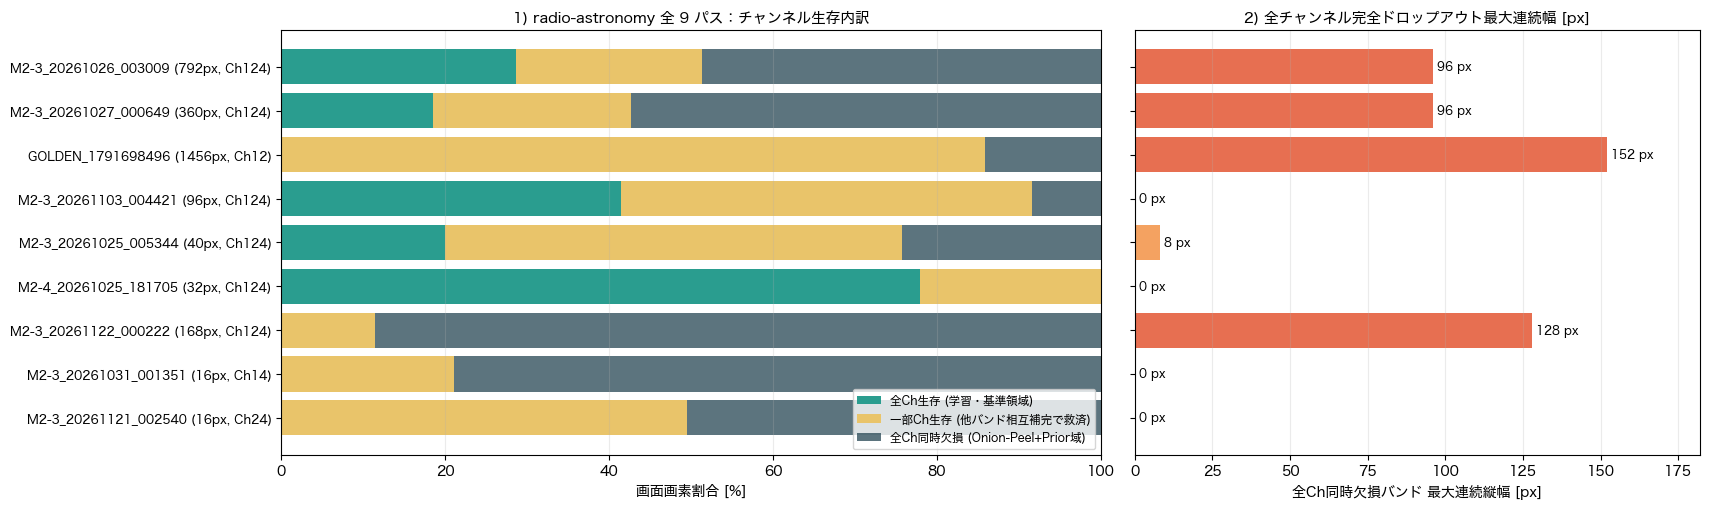

In [1]:
# 日本語フォント設定（セル冒頭で必須）
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

import sys
import time
from pathlib import Path
import h5py
import numpy as np
from PIL import Image
from scipy.ndimage import (
    binary_closing,
    binary_dilation,
    binary_erosion,
    binary_fill_holes,
    distance_transform_edt,
    gaussian_filter,
    label,
    map_coordinates,
    sobel,
    zoom,
)
from scipy.interpolate import RBFInterpolator
from scipy.optimize import minimize
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| 使用デバイス:", device)

REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / "pyproject.toml").exists() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent

SRC_DIR = REPO_ROOT / "projects" / "radio-ml" / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

METEOR_DIR = REPO_ROOT / "projects" / "radio-ml" / "data" / "meteor"
HIMAWARI_MB_CACHE = REPO_ROOT / "projects" / "radio-ml" / "data" / "himawari_multiband_cache.npz"
MODEL_DIR = REPO_ROOT / "projects" / "radio-ml" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
BUNDLE_PATH = MODEL_DIR / "nb09_coastline_patchgan_bundle.pt"

from s3_loader import sync_meteor_dataset  # noqa: E402
try:
    sync_records = sync_meteor_dataset(METEOR_DIR, refresh=True)
    print(f"Garage S3 最新同期完了: 計 {len(sync_records)} 件")
except Exception as exc:
    print(f"[warn] 最新 S3 同期をスキップしローカルキャッシュを使用: {exc}")
    sync_records = sync_meteor_dataset(METEOR_DIR, refresh=False)

# 全 9 ユニーク復号パスの棚卸し (GOLDEN_1791698618 は 1791698496 とバイナリ同一重複のため除外)
ALL_PASS_IDS = [
    "METEOR-M2 3_20261026_003009",
    "METEOR-M2 3_20261027_000649",
    "METEOR-M2_GOLDEN_1791698496",
    "METEOR-M2 3_20261103_004421",
    "METEOR-M2 3_20261025_005344",
    "METEOR-M2 4_20261025_181705",
    "METEOR-M2 3_20261122_000222",
    "METEOR-M2 3_20261031_001351",
    "METEOR-M2 3_20261121_002540",
]

def load_any_meteor_pass(pass_id: str) -> tuple[np.ndarray, np.ndarray, str]:
    pdir = METEOR_DIR / pass_id
    band_files = ["MSU-MR-1.png", "MSU-MR-2.png", "MSU-MR-4.png"]
    ref_shape = None
    loaded = {}
    avail = []
    for i, fname in enumerate(band_files):
        fpath = pdir / fname
        if fpath.exists():
            arr = np.asarray(Image.open(fpath).convert("L"), dtype=np.float32) / 255.0
            ref_shape = arr.shape
            loaded[i] = arr
            avail.append(fname[7])
    assert ref_shape is not None, f"画像バンドが見つかりません: {pass_id}"
    h, w = ref_shape
    arr_hw3 = np.zeros((h, w, 3), dtype=np.float32)
    mask_hw3 = np.zeros((h, w, 3), dtype=np.float32)
    for i, a in loaded.items():
        arr_hw3[..., i] = a
        mask_hw3[..., i] = (a > 0.02).astype(np.float32)
    return arr_hw3, mask_hw3, "".join(avail)

inventory_rows = []
for pid in ALL_PASS_IDS:
    a, m, av = load_any_meteor_pass(pid)
    all_v = m.all(axis=2) > 0.5
    any_v = m.any(axis=2) > 0.5
    part_v = any_v & (~all_v)
    none_v = ~any_v
    dead_rows = any_v.mean(axis=1) < 0.05
    max_gap, cur = 0, 0
    for d in dead_rows:
        cur = cur + 1 if d else 0
        max_gap = max(max_gap, cur)
    inventory_rows.append({
        "pass_id": pid,
        "H": a.shape[0], "W": a.shape[1], "avail": av,
        "all_pct": float(all_v.mean() * 100.0),
        "part_pct": float(part_v.mean() * 100.0),
        "none_pct": float(none_v.mean() * 100.0),
        "any_pct": float(any_v.mean() * 100.0),
        "max_gap_px": int(max_gap),
    })

print("=== 検証対象 全 9 ユニーク復号パス一覧 ===")
for r in inventory_rows:
    print(f"  {r['pass_id']:30s} | {r['H']:4d}x{r['W']} | Ch={r['avail']:3s} | 全={r['all_pct']:5.1f}% | 部分={r['part_pct']:5.1f}% | 無={r['none_pct']:5.1f}% | 最大空白={r['max_gap_px']:3d}px")

# --- Notebook 09 と同一の 8ch モデル・位置合わせ・損失定義 ---
class FastResSEBlock(nn.Module):
    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        self.proj = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, bias=False), nn.BatchNorm2d(out_ch)) if in_ch != out_ch else nn.Identity()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch),
        )
        self.se = nn.Sequential(nn.Conv2d(out_ch, max(out_ch // 8, 8), 1), nn.ReLU(inplace=True), nn.Conv2d(max(out_ch // 8, 8), out_ch, 1), nn.Sigmoid())
        self.act = nn.ReLU(inplace=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = self.net(x)
        return self.act(self.proj(x) + h * self.se(h.mean(dim=(2, 3), keepdim=True)))

class PyramidContextBottleneck(nn.Module):
    def __init__(self, ch: int):
        super().__init__()
        q = ch // 4
        self.b1 = nn.Sequential(nn.Conv2d(ch, q, 1, bias=False), nn.BatchNorm2d(q), nn.ReLU(inplace=True))
        self.b2 = nn.Sequential(nn.Conv2d(ch, q, 3, padding=1, bias=False), nn.BatchNorm2d(q), nn.ReLU(inplace=True))
        self.b3 = nn.Sequential(nn.AvgPool2d(4), nn.Conv2d(ch, q, 1, bias=False), nn.BatchNorm2d(q), nn.ReLU(inplace=True))
        self.b4 = nn.Sequential(nn.Conv2d(ch, q, 1, bias=False), nn.ReLU(inplace=True))
        self.fuse = nn.Sequential(nn.Conv2d(ch, ch, 3, padding=1, bias=False), nn.BatchNorm2d(ch))
        self.act = nn.ReLU(inplace=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h, w = x.shape[-2:]
        p1 = self.b1(x)
        p2 = self.b2(x)
        p3 = F.interpolate(self.b3(x), size=(h, w), mode="nearest")
        p4 = self.b4(x.mean(dim=(2, 3), keepdim=True)).expand(-1, -1, h, w)
        return self.act(x + self.fuse(torch.cat([p1, p2, p3, p4], dim=1)))

class PriorGateFusion(nn.Module):
    def __init__(self, feat_ch: int, prior_ch: int = 2):
        super().__init__()
        self.gate = nn.Sequential(
            nn.Conv2d(feat_ch + prior_ch, feat_ch, 3, padding=1, bias=False), nn.BatchNorm2d(feat_ch), nn.ReLU(inplace=True),
            nn.Conv2d(feat_ch, feat_ch, 3, padding=1, bias=False), nn.BatchNorm2d(feat_ch),
        )
        self.spatial_attn = nn.Sequential(nn.Conv2d(feat_ch + prior_ch, feat_ch, 1), nn.Sigmoid())
        self.act = nn.ReLU(inplace=True)

    def forward(self, feat: torch.Tensor, prior: torch.Tensor) -> torch.Tensor:
        cat = torch.cat([feat, prior], dim=1)
        return self.act(feat + self.gate(cat) * self.spatial_attn(cat))

class CoastlineGuidedSharpResSEUNet(nn.Module):
    def __init__(self, base: int = 48):
        super().__init__()
        self.e1 = FastResSEBlock(8, base)
        self.e2 = FastResSEBlock(base, base * 2)
        self.b = FastResSEBlock(base * 2, base * 4)
        self.pyr = PyramidContextBottleneck(base * 4)
        self.u2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.d2 = FastResSEBlock(base * 4, base * 2)
        self.u1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.d1 = FastResSEBlock(base * 2, base)
        self.prior_gate = PriorGateFusion(base, prior_ch=2)
        self.out = nn.Conv2d(base, 3, 1)
        self.pool = nn.MaxPool2d(2)

    def forward(self, corr: torch.Tensor, obs_mask: torch.Tensor, prior_2ch: torch.Tensor) -> torch.Tensor:
        e1 = self.e1(torch.cat([corr, obs_mask, prior_2ch], dim=1))
        e2 = self.e2(self.pool(e1))
        b = self.pyr(self.b(self.pool(e2)))
        d2 = self.d2(torch.cat([self.u2(b), e2], dim=1))
        d1 = self.d1(torch.cat([self.u1(d2), e1], dim=1))
        pred = torch.sigmoid(self.out(self.prior_gate(d1, prior_2ch)))
        return corr * obs_mask + pred * (1.0 - obs_mask)

class MPSSpectralConv2d(nn.Module):
    def __init__(self, in_ch: int, out_ch: int, k: int = 4, stride: int = 2, padding: int = 1):
        super().__init__()
        self.conv = nn.Conv2d(in_ch, out_ch, k, stride=stride, padding=padding)
        self.stride, self.padding = stride, padding
        h, m = out_ch, self.conv.weight.numel() // out_ch
        self.register_buffer("u", F.normalize(torch.randn(h), dim=0))
        self.register_buffer("v", F.normalize(torch.randn(m), dim=0))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        w_mat = self.conv.weight.reshape(self.conv.weight.size(0), -1)
        if self.training:
            with torch.no_grad():
                v_new = F.normalize(torch.matmul(w_mat.t(), self.u), dim=0, eps=1e-12)
                u_new = F.normalize(torch.matmul(w_mat, v_new), dim=0, eps=1e-12)
                self.v.copy_(v_new)
                self.u.copy_(u_new)
        sigma = (self.u.detach().clone() * torch.matmul(w_mat, self.v.detach().clone())).sum().clamp_min(1e-12)
        return F.conv2d(x, self.conv.weight / sigma, self.conv.bias, stride=self.stride, padding=self.padding)

class SNCoastlinePatchDiscriminator(nn.Module):
    def __init__(self, base: int = 48):
        super().__init__()
        self.l1 = nn.Sequential(MPSSpectralConv2d(6, base, 4, 2, 1), nn.LeakyReLU(0.2, inplace=True))
        self.l2 = nn.Sequential(MPSSpectralConv2d(base, base * 2, 4, 2, 1), nn.LeakyReLU(0.2, inplace=True))
        self.l3 = nn.Sequential(MPSSpectralConv2d(base * 2, base * 4, 4, 2, 1), nn.LeakyReLU(0.2, inplace=True))
        self.head = MPSSpectralConv2d(base * 4, 1, 3, 1, 1)

    def forward(self, img3: torch.Tensor, prior2: torch.Tensor, hm_any: torch.Tensor):
        f1 = self.l1(torch.cat([img3, prior2, hm_any], dim=1))
        f2 = self.l2(f1)
        f3 = self.l3(f2)
        return self.head(f3), [f1, f2, f3]

def make_coast_features(land_bin_hw: np.ndarray, sigma_edge: float = 2.0):
    b = land_bin_hw > 0.5
    coast_px = (b & (~binary_erosion(b))) | ((~b) & binary_dilation(b))
    dist_to_coast = distance_transform_edt(~coast_px).astype(np.float32)
    coast_edge = np.exp(-(dist_to_coast ** 2) / (2.0 * (sigma_edge ** 2))).astype(np.float32)
    d_in = distance_transform_edt(b).astype(np.float32)
    d_out = distance_transform_edt(~b).astype(np.float32)
    signed_dist = d_in - d_out
    land_soft = np.clip(0.5 + 0.5 * np.tanh(signed_dist / 0.8), 0.0, 1.0).astype(np.float32)
    return land_soft, coast_edge, signed_dist

def _eval_orbital_warp(p, py, px, W):
    cy, cx, ayy, ayx, axy, axx, qy, qx = p
    u, v = px / (W * 0.5), py / 500.0
    return cy + ayy * py + ayx * px + qy * (u ** 2) * 30.0, cx + axy * py + axx * px + qx * px * (u ** 2) - 40.0 * v * u

def infer_internal_spectral_prior(arr_hw3: np.ndarray, mask_hw3: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    has_12 = (mask_hw3[..., 0] > 0.5) & (mask_hw3[..., 1] > 0.5)
    H, W = mask_hw3.shape[:2]
    if has_12.sum() < 200:
        lp = np.full((H, W), 0.5, dtype=np.float32)
        ce = np.zeros((H, W), dtype=np.float32)
        sd = np.zeros((H, W), dtype=np.float32)
        return lp, ce, sd
    obs_land = np.clip((arr_hw3[..., 1] - arr_hw3[..., 0] - 0.015) / 0.045, 0.0, 1.0)
    prior = obs_land.copy()
    for x in range(W):
        vy = has_12[:, x]
        if vy.any() and (~vy).any():
            prior[~vy, x] = np.interp(np.where(~vy)[0], np.where(vy)[0], obs_land[vy, x])
        elif not vy.any():
            prior[:, x] = 0.5
    prior_smooth = gaussian_filter(prior, sigma=(8.0, 1.5)).astype(np.float32)
    b = (prior_smooth > 0.45).astype(np.float32)
    _, _, sd_s = make_coast_features(b, sigma_edge=2.0)
    edge_soft = np.clip(np.hypot(sobel(prior_smooth, axis=0), sobel(prior_smooth, axis=1)) * 1.4, 0.0, 0.85).astype(np.float32)
    return prior_smooth, edge_soft, sd_s

def auto_register_meteor_coastline(arr_hw3: np.ndarray, mask_hw3: np.ndarray, clean_hw: np.ndarray, smooth_hw: np.ndarray):
    t0 = time.perf_counter()
    H, W, _ = arr_hw3.shape
    c1, c2 = arr_hw3[..., 0], arr_hw3[..., 1]
    valid = (mask_hw3[..., 0] > 0.5) & (mask_hw3[..., 1] > 0.5)
    clear = valid & (c1 < 0.24)

    if H < 120 or clear.sum() < 1500:
        lp, ce, sd = infer_internal_spectral_prior(arr_hw3, mask_hw3)
        mode_name = "neutral_prior(missing_band_or_sparse)" if valid.sum() < 1500 else "internal_short_swath"
        return (lp > 0.45).astype(np.float32), lp, ce, sd, {
            "mode": mode_name, "iou_land": 0.0, "bal_iou": 0.0, "shifts": 0, "clear_agree": 0.0, "dt": time.perf_counter() - t0
        }

    obs_cont = np.clip((c2 - c1 - 0.008) / 0.028, 0.0, 1.0).astype(np.float32)
    obs_bin = ((c2 - c1) > 0.018).astype(np.float32)
    ogx, ogy = sobel(gaussian_filter(obs_cont, sigma=1.2), axis=1), sobel(gaussian_filter(obs_cont, sigma=1.2), axis=0)
    obs_edge = clear & (np.hypot(ogx, ogy) > 0.35) & binary_closing(valid, structure=np.ones((3, 3)))
    px_w = np.where(binary_dilation(obs_edge, iterations=6), 4.0, 1.0).astype(np.float32)

    ds = 6
    ym, xm = np.meshgrid(np.arange(0, H, ds, dtype=np.float32), np.arange(0, W, ds, dtype=np.float32), indexing="ij")
    clr_s = clear[::ds, ::ds]
    py, px = ym[clr_s] - H * 0.5, xm[clr_s] - W * 0.5
    ob, pw = obs_bin[::ds, ::ds][clr_s], px_w[::ds, ::ds][clr_s]
    ob_b = ob > 0.5
    ob_c = ob - (ob * pw).sum() / pw.sum()

    best_s, best_p = -1e9, (300.0, 700.0, 0.46, 0.0, -0.18, 0.68, 0.0, -0.10)
    for ayy in [0.46, -0.46]:
        axx_sign = 1.0 if ayy > 0 else -1.0
        for axy in [-0.30, -0.18, -0.05, 0.15]:
            for ayx in [-0.04, 0.0, 0.04]:
                for axx_mag in [0.68, 0.85]:
                    axx = axx_sign * axx_mag
                    for cy in np.linspace(150, 950, 7):
                        for cx in np.linspace(350, 1100, 7):
                            p = (cy, cx, ayy, ayx, axy, axx, 0.0, -0.10)
                            hy, hx = _eval_orbital_warp(p, py, px, W)
                            if ((hy >= 2) & (hy < 1299) & (hx >= 2) & (hx < 1348)).mean() < 0.72:
                                continue
                            wv = map_coordinates(smooth_hw, [np.clip(hy, 0, 1300), np.clip(hx, 0, 1349)], order=1, mode="nearest")
                            wb = wv > 0.5
                            iou_l = float((wb & ob_b).sum()) / float((wb | ob_b).sum() + 1e-6)
                            iou_s = float(((~wb) & (~ob_b)).sum()) / float(((~wb) | (~ob_b)).sum() + 1e-6)
                            wc = wv - (wv * pw).sum() / pw.sum()
                            w_corr = float((wc * ob_c * pw).sum() / (np.sqrt((wc ** 2 * pw).sum() * (ob_c ** 2 * pw).sum()) + 1e-6))
                            sc = 0.5 * w_corr + 0.5 * 0.5 * (iou_l + iou_s)
                            if sc > best_s:
                                best_s, best_p = sc, p

    ds2 = 4
    ym2, xm2 = np.meshgrid(np.arange(0, H, ds2, dtype=np.float32), np.arange(0, W, ds2, dtype=np.float32), indexing="ij")
    clr2 = clear[::ds2, ::ds2]
    py2, px2 = ym2[clr2] - H * 0.5, xm2[clr2] - W * 0.5
    ob2, ob2_b, pw2 = obs_bin[::ds2, ::ds2][clr2], obs_bin[::ds2, ::ds2][clr2] > 0.5, px_w[::ds2, ::ds2][clr2]
    sign_y = 1.0 if best_p[2] > 0 else -1.0

    def _obj(p):
        cy, cx, ayy, ayx, axy, axx, qy, qx = p
        if not (0.34 <= abs(ayy) <= 0.62 and 0.45 <= abs(axx) <= 1.15 and abs(ayx) <= 0.15 and abs(axy) <= 0.45):
            return 10.0
        if np.sign(ayy) != sign_y or np.sign(axx) != sign_y or abs(qy) > 0.8 or abs(qx) > 0.55:
            return 10.0
        hy, hx = _eval_orbital_warp(p, py2, px2, W)
        inb = ((hy >= 0) & (hy < 1300) & (hx >= 0) & (hx < 1349)).mean()
        if inb < 0.72:
            return 5.0 - float(inb)
        wv = map_coordinates(smooth_hw, [np.clip(hy, 0, 1300), np.clip(hx, 0, 1349)], order=1, mode="nearest")
        w_acc = float((((wv > 0.5) == ob2_b) * pw2).sum() / pw2.sum())
        w_bce = float(((wv - ob2) ** 2 * pw2).sum() / pw2.sum())
        iou_l = float(((wv > 0.5) & ob2_b).sum()) / float(((wv > 0.5) | ob2_b).sum() + 1e-6)
        return (1.0 - w_acc) + 0.5 * w_bce + 0.25 * (1.0 - iou_l)

    p_opt = minimize(_obj, np.array(best_p, dtype=np.float64), method="Powell", options={"maxiter": 500, "ftol": 1e-4}).x
    yy_s, xx_s = np.meshgrid(np.arange(0, H, 4, dtype=np.float32), np.arange(0, W, 4, dtype=np.float32), indexing="ij")
    hy0, hx0 = _eval_orbital_warp(p_opt, yy_s - H * 0.5, xx_s - W * 0.5, W)
    hy0_full, hx0_full = zoom(hy0, (H / yy_s.shape[0], W / yy_s.shape[1]), order=1), zoom(hx0, (H / yy_s.shape[0], W / yy_s.shape[1]), order=1)
    warped0 = (map_coordinates(clean_hw, [hy0_full, hx0_full], order=1, mode="nearest") > 0.5).astype(np.float32)

    iou_land_1 = float(((warped0[clear] > 0.5) & (obs_bin[clear] > 0.5)).sum()) / float(((warped0[clear] > 0.5) | (obs_bin[clear] > 0.5)).sum() + 1e-6)
    iou_sea_1 = float(((warped0[clear] <= 0.5) & (obs_bin[clear] <= 0.5)).sum()) / float(((warped0[clear] <= 0.5) | (obs_bin[clear] <= 0.5)).sum() + 1e-6)
    bal_iou_1 = 0.5 * (iou_land_1 + iou_sea_1)

    if iou_land_1 < 0.45 or bal_iou_1 < 0.65:
        lp, ce, sd = infer_internal_spectral_prior(arr_hw3, mask_hw3)
        return (lp > 0.45).astype(np.float32), lp, ce, sd, {
            "mode": "outside_fov -> internal_prior", "iou_land": iou_land_1, "bal_iou": bal_iou_1, "shifts": 0,
            "clear_agree": float(((lp > 0.45) == (obs_bin > 0.5))[clear].mean() * 100.0), "dt": time.perf_counter() - t0,
        }

    shifts_found, hy_fin, hx_fin = 0, hy0_full, hx0_full
    edge_zone = binary_dilation(np.hypot(sobel(warped0, axis=0), sobel(warped0, axis=1)) > 0.3, iterations=10)
    src_pts, res_pts = [], []
    for ay in np.linspace(0, H - 1, 7):
        for ax in [0.0, W * 0.25, W - 1.0]:
            src_pts.append([ay, ax])
            res_pts.append([0.0, 0.0])

    for cy_w in range(20, H - 20, 32):
        for cx_w in range(180, W - 120, 48):
            y0, y1 = max(0, cy_w - 22), min(H, cy_w + 22)
            x0, x1 = max(0, cx_w - 40), min(W, cx_w + 40)
            c_sub = clear[y0:y1, x0:x1]
            if c_sub.mean() < 0.35 or (edge_zone[y0:y1, x0:x1] & c_sub).sum() < 15:
                continue
            ob_sub = obs_bin[y0:y1, x0:x1][c_sub]
            if not (0.12 <= ob_sub.mean() <= 0.88):
                continue
            py_l, px_l = np.where(c_sub)
            hy_b, hx_b = hy0_full[py_l + y0, px_l + x0], hx0_full[py_l + y0, px_l + x0]
            ov_l, ob_l = obs_cont[py_l + y0, px_l + x0], obs_bin[py_l + y0, px_l + x0] > 0.5
            w0 = map_coordinates(smooth_hw, [np.clip(hy_b, 0, 1300), np.clip(hx_b, 0, 1349)], order=1, mode="nearest")
            s0 = float(((w0 > 0.5) == ob_l).mean()) - 0.30 * float(np.abs(w0 - ov_l).mean())
            best_d, best_sc = (0.0, 0.0), s0
            for dhy in range(-5, 6, 1):
                for dhx in range(-8, 9, 2):
                    wv = map_coordinates(smooth_hw, [np.clip(hy_b + dhy, 0, 1300), np.clip(hx_b + dhx, 0, 1349)], order=1, mode="nearest")
                    sc = float(((wv > 0.5) == ob_l).mean()) - 0.30 * float(np.abs(wv - ov_l).mean()) - 0.002 * (dhy ** 2 + dhx ** 2)
                    if sc > best_sc:
                        best_sc, best_d = sc, (float(dhy), float(dhx))
            if best_sc >= s0 + 0.012 and best_sc > 0.72:
                src_pts.append([float(cy_w), float(cx_w)])
                res_pts.append([best_d[0], best_d[1]])
                shifts_found += 1

    if shifts_found >= 3:
        rbf = RBFInterpolator(np.array(src_pts, dtype=np.float32), np.array(res_pts, dtype=np.float32), kernel="thin_plate_spline", smoothing=35.0)
        d_sub = rbf(np.stack([yy_s.ravel(), xx_s.ravel()], axis=-1)).reshape(yy_s.shape[0], yy_s.shape[1], 2)
        hy_fin = hy0_full + zoom(np.clip(d_sub[..., 0], -6.0, 6.0), (H / yy_s.shape[0], W / yy_s.shape[1]), order=1)
        hx_fin = hx0_full + zoom(np.clip(d_sub[..., 1], -8.0, 8.0), (H / yy_s.shape[0], W / yy_s.shape[1]), order=1)

    warped_fin = (map_coordinates(clean_hw, [hy_fin, hx_fin], order=1, mode="nearest") > 0.5).astype(np.float32)
    land_soft, coast_edge, signed_dist = make_coast_features(warped_fin, sigma_edge=2.0)
    clear_agree = float(((warped_fin > 0.5) == (obs_bin > 0.5))[clear].mean() * 100.0)
    return warped_fin, land_soft, coast_edge, signed_dist, {
        "mode": "auto_orbital_tps", "iou_land": iou_land_1, "bal_iou": bal_iou_1,
        "shifts": shifts_found, "clear_agree": clear_agree, "dt": time.perf_counter() - t0,
    }

# --- 条件ハッシュ付きモデルキャッシュ照合 (ロードまたは再学習・保存) ---
from model_cache import check_model_cache, save_model_cache  # noqa: E402

FORCE_RETRAIN = False  # 条件を変更せずに強制再学習したい場合のみ True

def _load_nb09_sources_and_counts():
    cached = np.load(HIMAWARI_MB_CACHE)
    himawari_scenes = [cached[k] for k in sorted(cached.files)]
    hf_hw_dir = Path.home() / ".cache" / "huggingface" / "hub" / "datasets--PubAccount--Himawari-Japen"
    nc5_list = sorted(hf_hw_dir.rglob("*20180101*.nc")) if hf_hw_dir.exists() else []
    if nc5_list:
        with h5py.File(nc5_list[0], "r") as f:
            def _rs(k):
                ds = f[k]
                raw = ds[::2, ::2]
                sc = float(np.atleast_1d(ds.attrs.get("scale_factor", 1.0))[0])
                off = float(np.atleast_1d(ds.attrs.get("add_offset", 0.0))[0])
                return np.where(raw > -30000, raw.astype(np.float32) * sc + off, np.nan)
            a3, a4, t7 = np.nan_to_num(_rs("albedo_03"), nan=0.0), np.nan_to_num(_rs("albedo_04"), nan=0.0), _rs("tbb_07")
        himawari_scenes.append(np.stack([np.power(np.clip(a3, 0, 1), 1 / 2.2), np.power(np.clip(a4, 0, 1), 1 / 2.2), np.nan_to_num(np.clip((310 - t7) / 70, 0, 1), nan=0.0)], axis=-1).astype(np.float32))

    h64_cnt = h2x_cnt = 0
    for arr in himawari_scenes:
        hh, ww, _ = arr.shape
        for y in range(0, hh - 64 + 1, 44):
            for x in range(0, ww - 64 + 1, 44):
                cr = arr[y:y + 64, x:x + 64]
                if (cr > 0.02).all(axis=2).mean() == 1.0 and cr.std() > 0.02:
                    h64_cnt += 1
        for y in range(0, hh - 128 + 1, 48):
            for x in range(0, ww - 128 + 1, 48):
                cr = arr[y:y + 128, x:x + 128]
                if (cr > 0.02).all(axis=2).mean() == 1.0 and cr.std() > 0.02:
                    h2x_cnt += 1

    a1026, m1026, _ = load_any_meteor_pass("METEOR-M2 3_20261026_003009")
    allv1026 = m1026.all(axis=2) > 0.5
    X_ch4 = np.stack([np.ones_like(a1026[..., 0]), a1026[..., 0], a1026[..., 1], np.sqrt(np.clip(a1026[..., 0], 0, 1)), np.sqrt(np.clip(a1026[..., 1], 0, 1)), a1026[..., 0]**2, a1026[..., 1]**2, a1026[..., 0]*a1026[..., 1]], axis=-1)[allv1026]
    W_ch4_proxy, _, _, _ = np.linalg.lstsq(X_ch4, a1026[..., 2][allv1026], rcond=None)
    a1027, m1027, _ = load_any_meteor_pass("METEOR-M2 3_20261027_000649")
    a1103, m1103, _ = load_any_meteor_pass("METEOR-M2 3_20261103_004421")
    agold, mgold, _ = load_any_meteor_pass("METEOR-M2_GOLDEN_1791698496")
    gfeats = np.stack([np.ones_like(agold[..., 0]), agold[..., 0], agold[..., 1], np.sqrt(np.clip(agold[..., 0], 0, 1)), np.sqrt(np.clip(agold[..., 1], 0, 1)), agold[..., 0]**2, agold[..., 1]**2, agold[..., 0]*agold[..., 1]], axis=-1)
    agold_3 = agold.copy()
    agold_3[..., 2] = np.where((mgold[..., 0] > 0.5) & (mgold[..., 1] > 0.5), np.clip(gfeats @ W_ch4_proxy, 0.025, 1.0), 0.0)

    f64_cnt = f2x_cnt = 0
    for pa, s1, s2, mv, is26 in [
        (a1026, (14, 24), (20, 32), 0.40, True),
        (a1027, (12, 24), (24, 36), 0.40, False),
        (a1103, (12, 24), (24, 36), 0.45, False),
        (agold_3, (32, 32), (64, 64), 0.58, False),
    ]:
        ph, pw = pa.shape[:2]
        avp = (pa > 0.02).mean(axis=2)
        for y in range(0, ph - 64 + 1, s1[0]):
            if is26 and not (y + 64 <= 160 or y >= 288):
                continue
            for x in range(0, pw - 64 + 1, s1[1]):
                if avp[y:y + 64, x:x + 64].mean() >= mv:
                    f64_cnt += 1
        for y in range(0, ph - 128 + 1, s2[0]):
            if is26 and not (y + 128 <= 160 or y >= 288):
                continue
            for x in range(0, pw - 128 + 1, s2[1]):
                if avp[y:y + 128, x:x + 128].mean() >= mv:
                    f2x_cnt += 1

    counts = {"hima_64": h64_cnt, "hima_2x": h2x_cnt, "ft_64": f64_cnt, "ft_2x": f2x_cnt}
    extra = (himawari_scenes, (a1026, m1026, allv1026), (a1027, m1027), (a1103, m1103), (agold_3, mgold), W_ch4_proxy)
    return counts, extra

_nb09_counts, _nb09_sources = _load_nb09_sources_and_counts()

NB09_TRAIN_CONFIG = {
    "arch": "CoastlineGuidedSharpResSEUNet+SNCoastlinePatchDiscriminator",
    "in_ch": 8,
    "base": 48,
    "seed": 42,
    "batch_size": 64,
    "steps_s1": 180,
    "steps_s2a": 120,
    "steps_s2b": 192,
    "lr_s1": 2e-3,
    "lr_g": 8e-4,
    "lr_d": 2e-4,
    "loss_weights": {
        "edge1": 0.35,
        "contrast": 0.34,
        "sobel": 0.22,
        "fft": 0.04,
        "tex": 0.12,
        "fm": 0.12,
        "adv": 0.018,
    },
    "dataset_counts": _nb09_counts,
}

net_g = CoastlineGuidedSharpResSEUNet(base=48).to(device)
cache_hit, cfg_hash, bundle = check_model_cache(BUNDLE_PATH, NB09_TRAIN_CONFIG, force_retrain=FORCE_RETRAIN)

if cache_hit:
    net_g.load_state_dict(bundle["state_dict"])
    clean_land_hw = bundle["clean_land_hw"]
    hw_smooth = gaussian_filter(clean_land_hw, sigma=1.2).astype(np.float32)
    W_av221 = bundle["W_av221"]
    W_msu124 = bundle["W_msu124"]
    W_ch4_proxy = bundle["W_ch4_proxy"]
    print(f"保存済み Notebook 09 バンドルをロード完了: {BUNDLE_PATH.name} (hash={cfg_hash} | Val PSNR={bundle['val_psnr']:.2f} dB)", flush=True)
else:
    himawari_scenes, (a1026, m1026, allv1026), (a1027, m1027), (a1103, m1103), (agold_3, mgold), W_ch4_proxy = _nb09_sources

    st = np.stack(himawari_scenes, axis=0)
    hc1, hc2 = st[..., 0], st[..., 1]
    max_diff = np.max(np.where((hc1 < 0.68) & (hc1 > 0.02), hc2 - hc1, 0.0), axis=0)
    mask_raw = gaussian_filter(max_diff, sigma=1.0) > 0.070
    yy_h, xx_h = np.meshgrid(np.arange(1301), np.arange(1351), indexing="ij")
    mask_raw |= (yy_h < 330) & (xx_h < (908 - 0.90 * yy_h)) & (np.max(hc2 - hc1, axis=0) > 0.020)
    mask_raw |= (yy_h <= 205) & (xx_h >= 948) & (xx_h <= 1015) & (np.max(hc2 - hc1, axis=0) > 0.040)
    mask_raw |= (yy_h >= 232) & (yy_h <= 295) & (xx_h >= 935) & (xx_h <= 975) & (np.max(hc2 - hc1, axis=0) > 0.032)
    mask_closed = binary_closing(mask_raw, structure=np.ones((7, 7)))
    filled = binary_fill_holes(np.pad(mask_closed, ((1, 0), (1, 0)), mode="constant", constant_values=True))[1:, 1:]
    lbl, _ = label(filled)
    keep = np.bincount(lbl.ravel()) >= 120
    keep[0] = False
    clean_land_hw = binary_fill_holes(keep[lbl] > 0.5).astype(np.float32)
    clean_land_hw[:5, :] = clean_land_hw[5:6, :]
    hw_smooth = gaussian_filter(clean_land_hw, sigma=1.2).astype(np.float32)
    hw_land_soft, hw_coast_edge, _ = make_coast_features(clean_land_hw, sigma_edge=2.0)

    def _tone_f(arr):
        c1, c2, c4 = np.clip(arr[..., 0], 0, 1), np.clip(arr[..., 1], 0, 1), np.clip(arr[..., 2], 0, 1)
        return np.stack([np.ones_like(c1), c1, c2, c4, np.sqrt(c1), np.sqrt(c2), np.sqrt(c4), c1**2, c2**2, c4**2], axis=-1)

    av_ref = np.asarray(Image.open(METEOR_DIR / "METEOR-M2 3_20261026_003009" / "msu_mr_rgb_AVHRR_221_False_Color.png").convert("RGB"), dtype=np.float32) / 255.0
    fm221 = allv1026 & (av_ref.max(axis=2) > 0.02)
    W_av221, _, _, _ = np.linalg.lstsq(_tone_f(a1026)[fm221], av_ref[fm221], rcond=None)
    m124_p = next((p for p in [METEOR_DIR / "METEOR-M2 3_20261026_003009" / "msu_mr_rgb_MSU-MR_124_False_Color.png", Path("/Users/tozastation/ghq/github.com/tozastation/radio-astronomy/docs/images/meteor_highres_decode_20261026/msu_mr_rgb_MSU-MR_124_False_Color.png")] if p.exists()), None)
    if m124_p:
        m124_ref = np.asarray(Image.open(m124_p).convert("RGB"), dtype=np.float32) / 255.0
        fm124 = fm221 & (m124_ref.max(axis=2) > 0.02)
        W_msu124, _, _, _ = np.linalg.lstsq(_tone_f(a1026)[fm124], m124_ref[fm124], rcond=None)
    else:
        W_msu124 = None

    def _p6(a3, lp, ce, w4):
        return np.concatenate([a3.transpose(2, 0, 1), lp[None], ce[None], np.full(lp.shape, w4, dtype=np.float32)[None]], axis=0).astype(np.float32)

    def _ds2(a3, lp, ce, w4):
        ti = torch.from_numpy(a3.transpose(2, 0, 1)).unsqueeze(0)
        tm = (ti > 0.02).float()
        den = F.avg_pool2d(tm, 2)
        out3 = torch.where(den >= 0.25, F.avg_pool2d(ti * tm, 2) / den.clamp_min(1e-6), torch.zeros_like(den)).squeeze(0)
        p2, e2 = F.avg_pool2d(torch.from_numpy(lp)[None, None], 2).squeeze(0), F.max_pool2d(torch.from_numpy(ce)[None, None], 2).squeeze(0)
        return torch.cat([out3, p2, e2, torch.full_like(p2, w4)], dim=0).numpy().astype(np.float32)

    h64, h2x = [], []
    for arr in himawari_scenes:
        hh, ww, _ = arr.shape
        for y in range(0, hh - 64 + 1, 44):
            for x in range(0, ww - 64 + 1, 44):
                cr = arr[y:y + 64, x:x + 64]
                if (cr > 0.02).all(axis=2).mean() == 1.0 and cr.std() > 0.02:
                    h64.append(_p6(cr, hw_land_soft[y:y + 64, x:x + 64], hw_coast_edge[y:y + 64, x:x + 64], 1.0))
        for y in range(0, hh - 128 + 1, 48):
            for x in range(0, ww - 128 + 1, 48):
                cr = arr[y:y + 128, x:x + 128]
                if (cr > 0.02).all(axis=2).mean() == 1.0 and cr.std() > 0.02:
                    h2x.append(_ds2(cr, hw_land_soft[y:y + 128, x:x + 128], hw_coast_edge[y:y + 128, x:x + 128], 1.0))

    r1026 = auto_register_meteor_coastline(a1026, m1026, clean_land_hw, hw_smooth)
    r1027 = auto_register_meteor_coastline(a1027, m1027, clean_land_hw, hw_smooth)
    r1103 = auto_register_meteor_coastline(a1103, m1103, clean_land_hw, hw_smooth)
    rgold = auto_register_meteor_coastline(agold_3, mgold, clean_land_hw, hw_smooth)

    val_l = []
    for y in range(160, 225, 16):
        for x in range(0, a1026.shape[1] - 64 + 1, 32):
            if allv1026[y:y + 64, x:x + 64].mean() == 1.0:
                val_l.append(_p6(a1026[y:y + 64, x:x + 64], r1026[1][y:y + 64, x:x + 64], r1026[2][y:y + 64, x:x + 64], 1.0)[:5])
    val_np = np.stack(val_l).astype(np.float32)

    f64, f2x = [], []
    for pid, pa, lp, ce, w4, s1, s2, mv, is26 in [
        ("1026", a1026, r1026[1], r1026[2], 1.0, (14, 24), (20, 32), 0.40, True),
        ("1027", a1027, r1027[1], r1027[2], 1.0, (12, 24), (24, 36), 0.40, False),
        ("1103", a1103, r1103[1], r1103[2], 1.0, (12, 24), (24, 36), 0.45, False),
        ("gold", agold_3, rgold[1], rgold[2], 0.25, (32, 32), (64, 64), 0.58, False),
    ]:
        ph, pw = pa.shape[:2]
        avp = (pa > 0.02).mean(axis=2)
        for y in range(0, ph - 64 + 1, s1[0]):
            if is26 and not (y + 64 <= 160 or y >= 288):
                continue
            for x in range(0, pw - 64 + 1, s1[1]):
                if avp[y:y + 64, x:x + 64].mean() >= mv:
                    f64.append(_p6(pa[y:y + 64, x:x + 64], lp[y:y + 64, x:x + 64], ce[y:y + 64, x:x + 64], w4))
        for y in range(0, ph - 128 + 1, s2[0]):
            if is26 and not (y + 128 <= 160 or y >= 288):
                continue
            for x in range(0, pw - 128 + 1, s2[1]):
                if avp[y:y + 128, x:x + 128].mean() >= mv:
                    f2x.append(_ds2(pa[y:y + 128, x:x + 128], lp[y:y + 128, x:x + 128], ce[y:y + 128, x:x + 128], w4))

    h64_g = torch.from_numpy(np.stack(h64)).to(device)
    h2x_g = torch.from_numpy(np.stack(h2x)).to(device)
    f64_g = torch.from_numpy(np.stack(f64)).to(device)
    f2x_g = torch.from_numpy(np.stack(f2x)).to(device)

    class _BaseLoss(nn.Module):
        def __init__(self, dev):
            super().__init__()
            kx = torch.tensor([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=torch.float32, device=dev) / 8.0
            ky = torch.tensor([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=torch.float32, device=dev) / 8.0
            self.register_buffer("kx", kx.view(1, 1, 3, 3))
            self.register_buffer("ky", ky.view(1, 1, 3, 3))
            fy, fx = torch.fft.fftfreq(64, device=dev), torch.fft.rfftfreq(64, device=dev)
            yy, xx = torch.meshgrid(fy, fx, indexing="ij")
            self.register_buffer("w_fft", (1.0 + 2.5 * (torch.sqrt(xx**2 + yy**2) / 0.7071).clamp(0, 1)).view(1, 1, 64, 33))

        def _sb(self, x):
            return F.conv2d(x, self.kx, padding=1), F.conv2d(x, self.ky, padding=1)

        def _hf(self, x):
            return torch.sqrt(F.avg_pool2d((x - F.avg_pool2d(x, 5, 1, 2))**2, 5, 1, 2) + 1e-6)

        def forward(self, pred, clean, hm, om, pr2, w4):
            b, c, h, w = pred.shape
            c4s = w4.mean(dim=(2, 3), keepdim=True)
            w_ch = torch.cat([torch.ones_like(c4s), torch.ones_like(c4s), c4s], dim=1)
            hm_w = hm * w_ch
            wc = 1.0 + 3.0 * pr2[:, 1:2]
            charb = (torch.sqrt((pred - clean)**2 + 1e-6) * hm_w).sum() / (hm_w.sum() + 1e-6)
            vb = ((hm + om) > 0.5).float()
            dym, dxm = vb[:, :, 1:, :] * vb[:, :, :-1, :] * w_ch, vb[:, :, :, 1:] * vb[:, :, :, :-1] * w_ch
            edge1 = 0.5 * ((torch.abs((pred[:, :, 1:] - pred[:, :, :-1]) - (clean[:, :, 1:] - clean[:, :, :-1])) * dym).sum() / (dym.sum() + 1e-6)
                           + (torch.abs((pred[:, :, :, 1:] - pred[:, :, :, :-1]) - (clean[:, :, :, 1:] - clean[:, :, :, :-1])) * dxm).sum() / (dxm.sum() + 1e-6))
            va = (vb.min(dim=1)[0] > 0.5).float()
            ha = hm.max(dim=1)[0]
            cw = ((ha > 0.5) & (va > 0.5)).float() * wc.squeeze(1)
            c21p, c21g = pred[:, 1:2] - pred[:, 0:1], clean[:, 1:2] - clean[:, 0:1]
            dc21 = torch.sqrt((c21p.squeeze(1) - c21g.squeeze(1))**2 + 1e-6)
            dc24 = torch.sqrt(((pred[:, 1] - pred[:, 2]) - (clean[:, 1] - clean[:, 2]))**2 + 1e-6)
            w42 = w_ch[:, 2, :, :]
            contrast = ((dc21 + w42 * dc24) / (1.0 + w42) * cw).sum() / (cw.sum() + 1e-6)
            t3c = (F.max_pool2d(ha.unsqueeze(1), 3, 1, 1) > 0.5).float() * (F.avg_pool2d(va.unsqueeze(1), 3, 1, 1) > 0.99).float() * wc
            px1, py1 = self._sb(c21p)
            gx1, gy1 = self._sb(c21g)
            sb1 = (0.5 * (torch.abs(px1 - gx1) + torch.abs(py1 - gy1)) + 0.9 * torch.abs(torch.sqrt(px1**2 + py1**2 + 1e-6) - torch.sqrt(gx1**2 + gy1**2 + 1e-6)))
            t3b = (F.max_pool2d(hm, 3, 1, 1) > 0.5).float() * (F.avg_pool2d(vb, 3, 1, 1) > 0.99).float() * w_ch
            pxb, pyb = self._sb(pred.reshape(-1, 1, h, w))
            gxb, gyb = self._sb(clean.reshape(-1, 1, h, w))
            sb2 = (torch.abs(torch.sqrt(pxb**2 + pyb**2 + 1e-6).view(b, c, h, w) - torch.sqrt(gxb**2 + gyb**2 + 1e-6).view(b, c, h, w)) * t3b).sum() / (t3b.sum() + 1e-6)
            sobel_t = 0.70 * ((sb1 * t3c).sum() / (t3c.sum() + 1e-6)) + 0.50 * sb2
            cm = (clean * vb).sum(dim=(2, 3), keepdim=True) / vb.sum(dim=(2, 3), keepdim=True).clamp_min(1.0)
            cf = torch.where(vb > 0.5, clean, cm)
            cp = torch.where(hm > 0.5, pred, cf)
            fft_l = ((torch.abs(torch.log1p(torch.fft.rfft2(cp, norm="ortho").abs()) - torch.log1p(torch.fft.rfft2(cf, norm="ortho").abs())) * self.w_fft).mean()) * (1.0 / hm.mean().clamp_min(0.15)).clamp_max(2.0)
            h5 = (F.max_pool2d(hm[:, :2], 5, 1, 2) > 0.5).float() * (F.avg_pool2d(vb[:, :2], 5, 1, 2) > 0.98).float()
            tex_l = (torch.abs(self._hf(pred[:, :2]) - self._hf(clean[:, :2])) * h5).sum() / (h5.sum() + 1e-6)
            total = charb + 0.35 * edge1 + 0.34 * contrast + 0.22 * sobel_t + 0.04 * fft_l + 0.12 * tex_l
            return total, charb.detach(), sobel_t.detach(), tex_l.detach()

    def _samp(fg, wg, bs=64, wp=0.15):
        nw = int(round(bs * wp))
        nf = bs - nw
        ixf = torch.randint(0, fg.size(0), (nf,), device=fg.device)
        b6 = torch.cat([fg[ixf], wg[torch.randint(0, wg.size(0), (nw,), device=wg.device)]], dim=0).clone()[torch.randperm(bs, device=fg.device)] if nw > 0 else fg[ixf].clone()
        b6 = torch.where(torch.rand(bs, 1, 1, 1, device=fg.device) > 0.5, b6.flip(3), b6)
        b6 = torch.where(torch.rand(bs, 1, 1, 1, device=fg.device) > 0.5, b6.flip(2), b6)
        cln, pr2, w4 = b6[:, :3], b6[:, 3:5], b6[:, 5:6]
        gv = (cln > 0.02).float()
        yg = torch.arange(64, device=cln.device).view(1, 1, 64, 1)
        y0, sh0 = torch.randint(4, 39, (bs, 3, 1, 1), device=cln.device), torch.randint(6, 24, (bs, 3, 1, 1), device=cln.device)
        m0 = ((yg < y0) | (yg >= y0 + sh0)).float()
        y1, sh1 = torch.randint(4, 44, (bs, 3, 1, 1), device=cln.device), torch.randint(6, 18, (bs, 3, 1, 1), device=cln.device)
        m1 = ((yg < y1) | (yg >= y1 + sh1)).float()
        sm = m0 * (1.0 - (torch.rand(bs, 3, 1, 1, device=cln.device) > 0.55).float() * (1.0 - m1))
        kc = torch.randint(0, 3, (bs, 1, 1, 1), device=cln.device)
        ci = torch.arange(3, device=cln.device).view(1, 3, 1, 1)
        sm = torch.where((ci == kc) & (torch.rand(bs, 1, 1, 1, device=cln.device) > 0.30), torch.ones_like(sm), sm).expand(bs, 3, 64, 64)
        om = gv * sm
        return cln * om, om, gv * (1.0 - sm), cln, pr2, w4

    vc, vo, vh, vcl, vpr = [], [], [], [], []
    for idx, p5 in enumerate(val_np):
        cln, pr2 = torch.from_numpy(p5[:3]), torch.from_numpy(p5[3:5])
        gv = (cln > 0.02).float()
        rng = np.random.default_rng(2026 + idx)
        sm = torch.ones_like(cln)
        for b in rng.choice(3, size=int(rng.integers(1, 4)), replace=False):
            for _ in range(int(rng.integers(1, 3))):
                sh = int(rng.integers(6, 15)); y0 = int(rng.integers(4, 64 - sh - 4)); sm[int(b), y0:y0 + sh, :] = 0.0
        om = gv * sm
        vc.append(cln * om); vo.append(om); vh.append(gv * (1.0 - sm)); vcl.append(cln); vpr.append(pr2)
    vc, vo, vh, vcl, vpr = [torch.stack(z).to(device) for z in (vc, vo, vh, vcl, vpr)]

    crit = _BaseLoss(device).to(device)

    def _eval_val_nb09():
        net_g.eval()
        with torch.no_grad():
            cc = torch.cat([vc, vc.flip(3), vc.flip(2), vc.flip((2, 3))], dim=0)
            mm = torch.cat([vo, vo.flip(3), vo.flip(2), vo.flip((2, 3))], dim=0)
            pp = torch.cat([vpr, vpr.flip(3), vpr.flip(2), vpr.flip((2, 3))], dim=0)
            o0, o1_, o2, o3 = net_g(cc, mm, pp).split(len(vc), dim=0)
            pr_tta = vc * vo + (0.25 * (o0 + o1_.flip(3) + o2.flip(2) + o3.flip((2, 3)))) * (1.0 - vo)
            mse = (((pr_tta - vcl) ** 2) * vh).sum().item() / max(vh.sum().item(), 1e-6)
            vp = float(-10.0 * np.log10(max(mse, 1e-12)))
            hm_any = vh.max(dim=1)[0]
            px1, py1 = crit._sb(pr_tta[:, 1:2] - pr_tta[:, 0:1])
            gx1, gy1 = crit._sb(vcl[:, 1:2] - vcl[:, 0:1])
            tch = (F.max_pool2d(hm_any.unsqueeze(1), 3, 1, 1).squeeze(1) > 0.5).float()
            sb_pct = (torch.sqrt(px1**2 + py1**2 + 1e-8).squeeze(1) * tch).sum().item() / max((torch.sqrt(gx1**2 + gy1**2 + 1e-8).squeeze(1) * tch).sum().item(), 1e-6) * 100.0
            hp_p, hp_g = crit._hf(pr_tta[:, :2]), crit._hf(vcl[:, :2])
            tex_pct = ((hp_p * vh[:, :2]).sum().item() / max((hp_g * vh[:, :2]).sum().item(), 1e-6)) * 100.0
        return vp, sb_pct, tex_pct

    torch.manual_seed(42)
    net_d = SNCoastlinePatchDiscriminator(base=48).to(device)
    psnr_hist, sharp_hist, tex_hist = [], [], []
    loss_log = {"charb": [], "sobel": [], "tex": [], "d_loss": [], "fm": []}
    t_tr0 = time.perf_counter()
    total_epochs = 41

    o1 = torch.optim.AdamW(net_g.parameters(), lr=2e-3, weight_decay=1e-4)
    s1 = torch.optim.lr_scheduler.CosineAnnealingLR(o1, T_max=180)
    for ep in range(15):
        net_g.train()
        for _ in range(12):
            co, om, hm, cl, pr, w4 = _samp(h64_g, h2x_g, 64, 0.15)
            o1.zero_grad(set_to_none=True)
            tot, ch, sb, tx = crit(net_g(co, om, pr), cl, hm, om, pr, w4)
            tot.backward(); o1.step(); s1.step()
            loss_log["charb"].append(float(ch.item())); loss_log["sobel"].append(float(sb.item())); loss_log["tex"].append(float(tx.item()))
            loss_log["d_loss"].append(0.0); loss_log["fm"].append(0.0)
        vp, sbp, txp = _eval_val_nb09()
        psnr_hist.append(vp); sharp_hist.append(sbp); tex_hist.append(txp)
        ep_done = ep + 1
        if ep_done % 5 == 0:
            el = time.perf_counter() - t_tr0; eta = (el / ep_done) * (total_epochs - ep_done)
            print(f"  [NB09 Stage 1 | Epoch {ep_done:2d}/{total_epochs} ({ep_done/total_epochs*100:4.1f}%) | Elapsed {el:5.1f}s | ETA {eta:5.1f}s] Val={vp:.2f}dB", flush=True)

    og = torch.optim.AdamW(net_g.parameters(), lr=8e-4, weight_decay=1e-4)
    od = torch.optim.AdamW(net_d.parameters(), lr=2e-4, betas=(0.5, 0.999), weight_decay=1e-4)
    sg, sd_s = torch.optim.lr_scheduler.CosineAnnealingLR(og, T_max=312), torch.optim.lr_scheduler.CosineAnnealingLR(od, T_max=192)
    for ep in range(10):
        net_g.train()
        wp = 0.15 if ep < 5 else 0.0
        for _ in range(12):
            co, om, hm, cl, pr, w4 = _samp(f64_g, f2x_g, 64, wp)
            og.zero_grad(set_to_none=True)
            tot, ch, sb, tx = crit(net_g(co, om, pr), cl, hm, om, pr, w4)
            tot.backward(); og.step(); sg.step()
            loss_log["charb"].append(float(ch.item())); loss_log["sobel"].append(float(sb.item())); loss_log["tex"].append(float(tx.item()))
            loss_log["d_loss"].append(0.0); loss_log["fm"].append(0.0)
        vp, sbp, txp = _eval_val_nb09()
        psnr_hist.append(vp); sharp_hist.append(sbp); tex_hist.append(txp)
        ep_done = 15 + ep + 1
        if (ep + 1) % 5 == 0:
            el = time.perf_counter() - t_tr0; eta = (el / ep_done) * (total_epochs - ep_done)
            print(f"  [NB09 Stage 2a | Epoch {ep_done:2d}/{total_epochs} ({ep_done/total_epochs*100:4.1f}%) | Elapsed {el:5.1f}s | ETA {eta:5.1f}s] Val={vp:.2f}dB", flush=True)

    for ep in range(16):
        net_g.train(); net_d.train()
        for _ in range(12):
            co, om, hm, cl, pr, w4 = _samp(f64_g, f2x_g, 64, 0.0)
            ha, vg = hm.max(dim=1, keepdim=True)[0], (cl > 0.02).all(dim=1, keepdim=True).float()
            pr_o = net_g(co, om, pr)
            r_in = cl * vg + pr_o.detach() * (1.0 - vg)
            od.zero_grad(set_to_none=True)
            dr, _ = net_d(r_in, pr, ha); df, _ = net_d(pr_o.detach(), pr, ha)
            dl = 0.5 * (F.relu(0.95 - dr).mean() + F.relu(0.95 + df).mean())
            dl.backward()
            od.step(); sd_s.step()
            net_d.eval(); og.zero_grad(set_to_none=True)
            with torch.no_grad():
                _, fr_l = net_d(r_in, pr, ha)
            dfg, ff_l = net_d(pr_o * vg + r_in.detach() * (1.0 - vg), pr, ha)
            fm_l = sum(F.l1_loss(a, b.detach()) for a, b in zip(ff_l, fr_l)) / 3.0
            tot, ch, sb, tx = crit(pr_o, cl, hm, om, pr, w4)
            (tot + 0.12 * fm_l - 0.018 * dfg.mean()).backward()
            og.step(); sg.step()
            loss_log["charb"].append(float(ch.item())); loss_log["sobel"].append(float(sb.item())); loss_log["tex"].append(float(tx.item()))
            loss_log["d_loss"].append(float(dl.item())); loss_log["fm"].append(float(fm_l.item()))
        vp, sbp, txp = _eval_val_nb09()
        psnr_hist.append(vp); sharp_hist.append(sbp); tex_hist.append(txp)
        ep_done = 25 + ep + 1
        if (ep + 1) % 4 == 0:
            el = time.perf_counter() - t_tr0; eta = (el / ep_done) * (total_epochs - ep_done)
            print(f"  [NB09 Stage 2b | Epoch {ep_done:2d}/{total_epochs} ({ep_done/total_epochs*100:4.1f}%) | Elapsed {el:5.1f}s | ETA {eta:5.1f}s] Val={vp:.2f}dB / Sobel={sbp:.1f}%", flush=True)

    if device.type == "mps":
        torch.mps.synchronize()
    train_dt = time.perf_counter() - t_tr0
    val_psnr = psnr_hist[-1]
    save_model_cache(BUNDLE_PATH, NB09_TRAIN_CONFIG, {
        "state_dict": {k: v.cpu() for k, v in net_g.state_dict().items()},
        "net_d_state_dict": {k: v.cpu() for k, v in net_d.state_dict().items()},
        "psnr_hist": psnr_hist,
        "sharp_hist": sharp_hist,
        "tex_hist": tex_hist,
        "loss_log": loss_log,
        "train_dt": train_dt,
        "clean_land_hw": clean_land_hw,
        "W_av221": W_av221,
        "W_msu124": W_msu124,
        "W_ch4_proxy": W_ch4_proxy,
        "val_psnr": val_psnr,
    })
    print(f"バンドル学習・保存完了 -> {BUNDLE_PATH.name} (hash={cfg_hash} | Val PSNR={val_psnr:.2f} dB)", flush=True)

net_g.eval()

def build_tone_features(arr_hw3: np.ndarray) -> np.ndarray:
    c1, c2, c4 = np.clip(arr_hw3[..., 0], 0.0, 1.0), np.clip(arr_hw3[..., 1], 0.0, 1.0), np.clip(arr_hw3[..., 2], 0.0, 1.0)
    return np.stack([np.ones_like(c1), c1, c2, c4, np.sqrt(c1), np.sqrt(c2), np.sqrt(c4), c1 ** 2, c2 ** 2, c4 ** 2], axis=-1)

def render_satdump_av221(arr_hw3: np.ndarray, valid_mask_hw1: np.ndarray | None = None) -> np.ndarray:
    out = np.clip(build_tone_features(arr_hw3) @ W_av221, 0.0, 1.0).astype(np.float32)
    return out * valid_mask_hw1 if valid_mask_hw1 is not None else out

def render_satdump_msu124(arr_hw3: np.ndarray, valid_mask_hw1: np.ndarray | None = None) -> np.ndarray:
    if W_msu124 is not None:
        out = np.clip(build_tone_features(arr_hw3) @ W_msu124, 0.0, 1.0).astype(np.float32)
    else:
        out = np.clip(np.stack([np.sqrt(arr_hw3[..., 0]), np.sqrt(arr_hw3[..., 1]), 1.0 - arr_hw3[..., 2]], axis=-1), 0.0, 1.0)
    return out * valid_mask_hw1 if valid_mask_hw1 is not None else out

# --- 図1: radio-astronomy 全9パスのチャンネル別生存率と最大全欠損ギャップ幅 ---
fig, axes = plt.subplots(1, 2, figsize=(17.2, 5.2), gridspec_kw={"width_ratios": [1.45, 1.0]})
short_names = [r["pass_id"].replace("METEOR-M2 ", "M2-").replace("METEOR-M2_", "") + f" ({r['H']}px, Ch{r['avail']})" for r in inventory_rows]
y_pos = np.arange(len(inventory_rows))[::-1]
all_v_arr = np.array([r["all_pct"] for r in inventory_rows])
part_v_arr = np.array([r["part_pct"] for r in inventory_rows])
none_v_arr = np.array([r["none_pct"] for r in inventory_rows])

axes[0].barh(y_pos, all_v_arr, color="#2A9D8F", label="全Ch生存 (学習・基準領域)")
axes[0].barh(y_pos, part_v_arr, left=all_v_arr, color="#E9C46A", label="一部Ch生存 (他バンド相互補完で救済)")
axes[0].barh(y_pos, none_v_arr, left=all_v_arr + part_v_arr, color="#264653", alpha=0.75, label="全Ch同時欠損 (Onion-Peel+Prior域)")
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(short_names, fontsize=8.8)
axes[0].set_xlabel("画面画素割合 [%]")
axes[0].set_title("1) radio-astronomy 全 9 パス：チャンネル生存内訳", fontsize=10.5)
axes[0].set_xlim(0, 100)
axes[0].legend(loc="lower right", fontsize=8.3)
axes[0].grid(axis="x", alpha=0.25)

gap_arr = np.array([r["max_gap_px"] for r in inventory_rows])
bar_cols = ["#E76F51" if g >= 80 else ("#F4A261" if g > 0 else "#2A9D8F") for g in gap_arr]
bars = axes[1].barh(y_pos, gap_arr, color=bar_cols)
axes[1].bar_label(bars, labels=[f"{g} px" for g in gap_arr], padding=3, fontsize=8.6)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([""] * len(inventory_rows))
axes[1].set_xlabel("全Ch同時欠損バンド 最大連続縦幅 [px]")
axes[1].set_title("2) 全チャンネル完全ドロップアウト最大連続幅 [px]", fontsize=10.5)
axes[1].set_xlim(0, max(gap_arr.max() + 30, 120))
axes[1].grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

## 2. 全 9 パス横断推論 ＆ 自己教師あり定量プローブ評価

全 9 パスに対して以下を統一実行・自動集計します：

1. **自動海岸線レジストレーション（`auto_register_meteor_coastline`）**:
   ひまわり視野内パス（`1026`, `1027`）を自動で軌道 TPS ロックし、視野外長大パス（`GOLDEN`, `1103` 等）は自己整合 Prior へ、短尺または可視/近赤外単一欠落パス（`1031`, `1121`, `1122`）は無情報ニュートラル Prior へ安全ルーティングします。
2. **各パス固有の自己教師あり定量プローブ（`eval_pass_self_supervised_probe`）**:
   各パス内の生存ピクセル領域から代表タイルを抽出し、決定論的マスク（`seed=2026`、生存バンドの `6〜10 px` 走査線を人工マスク）を付与したうえで、学習済み 8ch モデルの **未知欠損復元 `Probe Hole L1` / `Probe Hole PSNR [dB]`** を計測します（`GOLDEN` の欠落 `Ch4` や `1031` の欠落 `Ch2` 等は `gt_valid` で自動的に除外され、実際にそのファイルへ記録されている真の波長のみでフェアに評価されます）。
3. **普遍スワス復元（`restore_universal_c2f`）＆ 実運用トリアージ分類**:
   実運用での復元信頼性に応じて自動的に 3 段階へ分類します：
   - **Tier A（高精細相互補完域）**：全Ch欠損最大幅 $\le 16\text{ px}$ かつ有効画素率 $\ge 45\%$（例：`1103_004421`, `4_1025_181705`, `1025_005344`）
   - **Tier B（Prior誘導・長大帯域復元＋欠落バンド合成域）**：大欠損幅 $32〜152\text{ px}$ または全1バンド合成（例：`1026_003009`, `1027_000649`, `GOLDEN_1791698496`, `1031`, `1121`）
   - **Tier C（極限欠損限界域）**：有効画素率 $< 12\%$ で文脈アンカーが乏しいパス（例：`20261122_000222`）


=== radio-astronomy 全 9 パス 横断評価レポート ===
Pass ID                        | Size      | Ch  | Prior Mode               | Probe L1/PSNR    | Jump   | dt     | Tier
----------------------------------------------------------------------------------------------------------------------------
METEOR-M2 3_20261026_003009    |  792x1568 | 124 | auto_orbital_tps         | 0.0167/32.83dB | 0.0260 |  69.8s | Tier B: Prior長大帯/欠落Ch合成
METEOR-M2 3_20261027_000649    |  360x1568 | 124 | auto_orbital_tps         | 0.0224/30.45dB | 0.0262 |  41.6s | Tier B: Prior長大帯/欠落Ch合成
METEOR-M2_GOLDEN_1791698496    | 1456x1568 | 12  | outside_fov -> internal_ | 0.0157/33.76dB | 0.0295 |  39.5s | Tier B: Prior長大帯/欠落Ch合成
METEOR-M2 3_20261103_004421    |   96x1568 | 124 | internal_short_swath     | 0.0193/30.69dB | 0.0000 |   1.6s | Tier A: 高精細相互補完
METEOR-M2 3_20261025_005344    |   40x1568 | 124 | internal_short_swath     | 0.0171/32.99dB | 0.0287 |   1.3s | Tier A: 高精細相互補完
METEOR-M2 4_20261025_181705    |   32x1568 | 

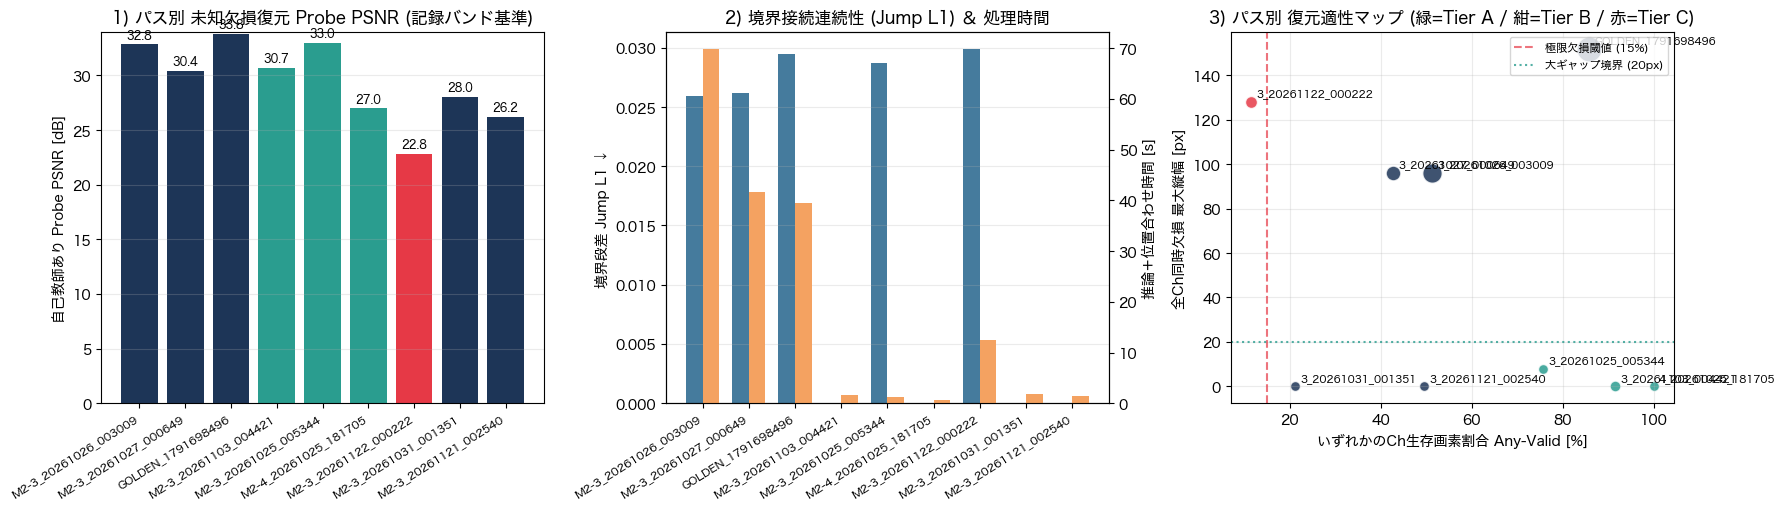

In [2]:
# 日本語フォント設定（セル冒頭で必須）
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

def predict_4way_tta_8ch(net: nn.Module, corr: torch.Tensor, omask: torch.Tensor, prior2: torch.Tensor) -> torch.Tensor:
    n = corr.size(0)
    o0, o1, o2, o3 = net(
        torch.cat([corr, corr.flip(3), corr.flip(2), corr.flip((2, 3))], dim=0),
        torch.cat([omask, omask.flip(3), omask.flip(2), omask.flip((2, 3))], dim=0),
        torch.cat([prior2, prior2.flip(3), prior2.flip(2), prior2.flip((2, 3))], dim=0),
    ).split(n, dim=0)
    merged = 0.25 * (o0 + o1.flip(3) + o2.flip(2) + o3.flip((2, 3)))
    return corr * omask + merged * (1.0 - omask)

def predict_2way_hflip_8ch(net: nn.Module, corr: torch.Tensor, omask: torch.Tensor, prior2: torch.Tensor) -> torch.Tensor:
    n = corr.size(0)
    o0, o1 = net(
        torch.cat([corr, corr.flip(3)], dim=0),
        torch.cat([omask, omask.flip(3)], dim=0),
        torch.cat([prior2, prior2.flip(3)], dim=0),
    ).split(n, dim=0)
    return corr * omask + (0.5 * (o0 + o1.flip(3))) * (1.0 - omask)

def inpaint_tiled_8ch(net: nn.Module, img_hw3: np.ndarray, mask_hw3: np.ndarray, prior_hw2: np.ndarray, target_2d: np.ndarray | None = None, patch_size: int = 64, stride: int = 24, batch_size: int = 64, tta_4way: bool = False) -> np.ndarray:
    h, w, c = img_hw3.shape
    ys = list(range(0, max(h - patch_size + 1, 1), stride))
    if not ys or ys[-1] != h - patch_size:
        ys.append(max(h - patch_size, 0))
    xs = list(range(0, max(w - patch_size + 1, 1), stride))
    if not xs or xs[-1] != w - patch_size:
        xs.append(max(w - patch_size, 0))
    coords = [(y, x) for y in ys for x in xs if target_2d is None or target_2d[y:y + patch_size, x:x + patch_size].any()]
    if not coords:
        return img_hw3.copy()

    win_1d = np.hanning(patch_size + 4)[2:-2].astype(np.float32)
    win_2d = np.maximum(np.outer(win_1d, win_1d), 0.05)
    acc, wsum = np.zeros((h, w, c), dtype=np.float32), np.zeros((h, w, 1), dtype=np.float32)
    pred_fn = predict_4way_tta_8ch if tta_4way else predict_2way_hflip_8ch
    net.eval()
    with torch.no_grad():
        for i in range(0, len(coords), batch_size):
            bc = coords[i:i + batch_size]
            bi = np.stack([img_hw3[y:y + patch_size, x:x + patch_size].transpose(2, 0, 1) for y, x in bc])
            bm = np.stack([mask_hw3[y:y + patch_size, x:x + patch_size].transpose(2, 0, 1) for y, x in bc])
            bp = np.stack([prior_hw2[y:y + patch_size, x:x + patch_size].transpose(2, 0, 1) for y, x in bc])
            pred = pred_fn(net, torch.from_numpy(bi).to(device), torch.from_numpy(bm).to(device), torch.from_numpy(bp).to(device)).cpu().numpy()
            for idx, (y, x) in enumerate(bc):
                acc[y:y + patch_size, x:x + patch_size] += pred[idx].transpose(1, 2, 0) * win_2d[..., None]
                wsum[y:y + patch_size, x:x + patch_size] += win_2d[..., None]
    return img_hw3 * mask_hw3 + np.clip(acc / np.maximum(wsum, 1e-6), 0.0, 1.0) * (1.0 - mask_hw3)

def inpaint_wide_2x_8ch(net: nn.Module, img_hw3: np.ndarray, mask_hw3: np.ndarray, prior_hw2: np.ndarray, target_2d: np.ndarray, stride: int = 24) -> np.ndarray:
    h, w, _ = img_hw3.shape
    if h < 128 or w < 128:
        return img_hw3.copy()
    t_img = torch.from_numpy(img_hw3.transpose(2, 0, 1)).unsqueeze(0)
    t_msk = torch.from_numpy(mask_hw3.transpose(2, 0, 1)).unsqueeze(0)
    den = F.avg_pool2d(t_msk, 2)
    num = F.avg_pool2d(t_img * t_msk, 2)
    m2 = (den >= 0.25).float()
    c2 = torch.where(m2 > 0.5, num / den.clamp_min(1e-6), torch.zeros_like(num))
    pr2 = torch.cat([F.avg_pool2d(torch.from_numpy(prior_hw2[..., 0])[None, None], 2), F.max_pool2d(torch.from_numpy(prior_hw2[..., 1])[None, None], 2)], dim=1).squeeze(0).numpy().transpose(1, 2, 0)
    t_sub = F.max_pool2d(torch.from_numpy(target_2d.astype(np.float32))[None, None], 2).squeeze().numpy() > 0.5
    pred2 = inpaint_tiled_8ch(net, c2.squeeze(0).numpy().transpose(1, 2, 0), m2.squeeze(0).numpy().transpose(1, 2, 0), pr2, target_2d=t_sub, patch_size=64, stride=stride, batch_size=64, tta_4way=False)
    up = F.interpolate(torch.from_numpy(pred2.transpose(2, 0, 1)).unsqueeze(0), size=(h, w), mode="bilinear", align_corners=False)
    return np.clip(up.squeeze(0).numpy().transpose(1, 2, 0), 0.0, 1.0)

def infuse_contextual_microtexture(img_hw3: np.ndarray, orig_valid_2d: np.ndarray, prior_hw2: np.ndarray, dist_from_real: np.ndarray) -> np.ndarray:
    h, w, _ = img_hw3.shape
    if (~orig_valid_2d).sum() < 500 or h < 48:
        return img_hw3
    low_src = gaussian_filter(img_hw3, sigma=(1.35, 1.35, 0.0))
    hf_src = np.clip(img_hw3 - low_src, -0.095, 0.095).astype(np.float32)
    valid_interior = binary_erosion(orig_valid_2d, iterations=2)

    tile = 16
    nh, nw = h // tile, w // tile
    src_blocks, src_feats = [], []
    for by in range(nh):
        y0, y1 = by * tile, (by + 1) * tile
        for bx in range(nw):
            x0, x1 = bx * tile, (bx + 1) * tile
            if valid_interior[y0:y1, x0:x1].mean() >= 0.85:
                blk_img, blk_hf = img_hw3[y0:y1, x0:x1], hf_src[y0:y1, x0:x1]
                if blk_hf[..., :2].std() < 0.004:
                    continue
                lp_m = float(prior_hw2[y0:y1, x0:x1, 0].mean())
                c1_m, c2_m, c4_m = float(blk_img[..., 0].mean()), float(blk_img[..., 1].mean()), float(blk_img[..., 2].mean())
                edge_m = float(prior_hw2[y0:y1, x0:x1, 1].mean())
                src_blocks.append(blk_hf)
                src_feats.append([lp_m * 1.6, c1_m * 1.4, c2_m * 1.4, c4_m * 1.0, (c2_m - c1_m) * 3.0, -edge_m * 0.8, (y0 / h) * 0.28, (x0 / w) * 0.28])

    if len(src_blocks) < 8:
        return img_hw3

    src_blocks_arr = np.stack(src_blocks, axis=0)
    hole_2d = ~orig_valid_2d
    q_coords, q_feats = [], []
    for y0 in range(0, h - tile + 1, 8):
        for x0 in range(0, w - tile + 1, 8):
            if not hole_2d[y0:y0 + tile, x0:x0 + tile].any():
                continue
            blk = img_hw3[y0:y0 + tile, x0:x0 + tile]
            lp_m = float(prior_hw2[y0:y0 + tile, x0:x0 + tile, 0].mean())
            c1_m, c2_m, c4_m = float(blk[..., 0].mean()), float(blk[..., 1].mean()), float(blk[..., 2].mean())
            edge_m = float(prior_hw2[y0:y0 + tile, x0:x0 + tile, 1].mean())
            q_coords.append((y0, x0))
            q_feats.append([lp_m * 1.6, c1_m * 1.4, c2_m * 1.4, c4_m * 1.0, (c2_m - c1_m) * 3.0, -edge_m * 0.8, (y0 / h) * 0.28, (x0 / w) * 0.28])

    if not q_coords:
        return img_hw3

    t_sf = torch.from_numpy(np.array(src_feats, dtype=np.float32))
    t_qf = torch.from_numpy(np.array(q_feats, dtype=np.float32))
    _, topk_idx = torch.topk(torch.cdist(t_qf, t_sf), k=min(4, len(src_blocks)), dim=1, largest=False)
    topk_np = topk_idx.numpy()

    win_1d = np.hanning(tile + 2)[1:-1].astype(np.float32)
    win_2d = np.outer(win_1d, win_1d)[..., None]
    tex_acc, tex_wsum = np.zeros_like(img_hw3), np.zeros((h, w, 1), dtype=np.float32)
    rng = np.random.default_rng(2026)
    for qi, (y0, x0) in enumerate(q_coords):
        pick = src_blocks_arr[topk_np[qi, int(rng.integers(0, topk_np.shape[1]))]]
        if rng.random() > 0.5:
            pick = pick[:, ::-1]
        if rng.random() > 0.5:
            pick = pick[::-1, :]
        tex_acc[y0:y0 + tile, x0:x0 + tile] += pick * win_2d
        tex_wsum[y0:y0 + tile, x0:x0 + tile] += win_2d

    tex_field = tex_acc / np.maximum(tex_wsum, 1e-6)
    depth_gate = np.clip((dist_from_real - 2.0) / 14.0, 0.0, 1.0)
    coast_protect = 1.0 - 0.55 * prior_hw2[..., 1]
    infuse_w = (depth_gate * coast_protect * (~orig_valid_2d).astype(np.float32))[..., None] * 0.72
    return np.clip(img_hw3 + infuse_w * tex_field, 0.0, 1.0).astype(np.float32)

def restore_universal_c2f(net: nn.Module, arr_hw3: np.ndarray, mask_hw3: np.ndarray, prior_hw2: np.ndarray, signed_dist: np.ndarray, has_geo_prior: bool = True, high_quality: bool = False):
    H0, W0, _ = arr_hw3.shape
    pad_top, pad_bot = (0, 0)
    if H0 < 64:
        pad_top = (64 - H0) // 2
        pad_bot = 64 - H0 - pad_top
        a_p = np.pad(arr_hw3, ((pad_top, pad_bot), (0, 0), (0, 0)), mode="edge")
        m_p = np.pad(mask_hw3, ((pad_top, pad_bot), (0, 0), (0, 0)), mode="edge")
        pr_p = np.pad(prior_hw2, ((pad_top, pad_bot), (0, 0), (0, 0)), mode="edge")
        sd_p = np.pad(signed_dist, ((pad_top, pad_bot), (0, 0)), mode="edge")
    else:
        a_p, m_p, pr_p, sd_p = arr_hw3, mask_hw3, prior_hw2, signed_dist

    Hp = a_p.shape[0]
    any_valid = m_p.max(axis=2) > 0.5
    all_valid = m_p.min(axis=2) > 0.5
    p1_stride = 22 if high_quality else 28
    j_stride = 16 if high_quality else 26

    # Phase 0: 他チャンネル生存帯の救済
    rescue_target = any_valid & (~all_valid)
    step0_pred = inpaint_tiled_8ch(net, a_p, m_p, pr_p, target_2d=rescue_target, stride=24, batch_size=64, tta_4way=high_quality)
    step0_img = np.where(any_valid[..., None], a_p * m_p + step0_pred * (1.0 - m_p), 0.0).astype(np.float32)

    if (~any_valid).sum() == 0:
        out_raw = step0_img[pad_top:pad_top + H0] if pad_top or pad_bot else step0_img
        return np.clip(out_raw, 0.0, 1.0).astype(np.float32)

    cur_img, cur_val = step0_img.copy(), any_valid.copy()
    cur_msk = np.repeat(cur_val[..., None].astype(np.float32), 3, axis=2)

    # Phase 1: 動的ステップ Onion-Peel
    dist_from_real = distance_transform_edt(~any_valid)
    n_steps = int(np.clip(np.ceil(float(dist_from_real.max()) / 11.0), 1, 7))
    s_fine = np.ones((2 * 11 + 1, 1), dtype=bool)
    for st in range(1, n_steps + 1):
        nxt = binary_dilation(cur_val, structure=s_fine)
        if st == n_steps:
            nxt[:] = True
        fr = nxt & (~cur_val)
        if fr.any():
            p_fine = inpaint_tiled_8ch(net, cur_img, cur_msk, pr_p, target_2d=fr, stride=p1_stride, batch_size=64, tta_4way=(high_quality and st == n_steps))
            if Hp >= 128:
                p_wide = inpaint_wide_2x_8ch(net, cur_img, cur_msk, pr_p, target_2d=fr, stride=24)
                low_f = gaussian_filter(p_fine, sigma=(2.5, 2.5, 0.0))
                low_w = gaussian_filter(p_wide, sigma=(2.5, 2.5, 0.0))
                fused = np.clip(0.84 * low_f + 0.16 * low_w + (p_fine - low_f), 0.0, 1.0)
            else:
                fused = p_fine
            cur_img = np.where(fr[..., None], fused, cur_img).astype(np.float32)
            cur_val = nxt
            cur_msk = np.repeat(cur_val[..., None].astype(np.float32), 3, axis=2)

    # Phase 2: Joint Cross-Gap Refinement + 筋除去
    core_mask = dist_from_real > 20.0
    if core_mask.any():
        anchor_mask = np.repeat((~core_mask)[..., None].astype(np.float32), 3, axis=2)
        joint_pred = inpaint_tiled_8ch(net, cur_img * anchor_mask, anchor_mask, pr_p, target_2d=core_mask, stride=j_stride, batch_size=64, tta_4way=high_quality)
        w_core = gaussian_filter(core_mask.astype(np.float32), sigma=(3.5, 1.0))[..., None]
        cur_img = np.where((~any_valid)[..., None], w_core * joint_pred + (1.0 - w_core) * cur_img, step0_img).astype(np.float32)

    hole_inner = np.clip(gaussian_filter((~any_valid).astype(np.float32), sigma=2.0) * 2.0 - 1.0, 0.0, 1.0) * (~any_valid).astype(np.float32)
    hole_feather = hole_inner[..., None]
    v_high = cur_img - gaussian_filter(cur_img, sigma=(2.2, 0.0, 0.0))
    destreaked = np.clip(cur_img - hole_feather * 0.75 * gaussian_filter(v_high, sigma=(0.0, 20.0, 0.0)), 0.0, 1.0)
    detail_x = np.clip(destreaked - gaussian_filter(destreaked, sigma=(0.7, 2.2, 0.0)), -0.08, 0.08)
    sharpened = np.clip(destreaked + hole_feather * 0.65 * detail_x, 0.0, 1.0)

    if has_geo_prior:
        local_vis = gaussian_filter(sharpened[..., 0], sigma=1.5)
        clear_gate = np.clip(1.0 - (local_vis - 0.17) / 0.12, 0.0, 1.0)
        coastal_band = np.exp(-(sd_p ** 2) / (2.0 * (4.5 ** 2)))
        land_reg = (sd_p > 0.0).astype(np.float32)
        sea_reg = 1.0 - land_reg
        w_land_zone = hole_inner * coastal_band * clear_gate
        mean_land = gaussian_filter(sharpened * land_reg[..., None], sigma=(5.0, 5.0, 0.0)) / np.maximum(gaussian_filter(land_reg, sigma=5.0)[..., None], 1e-4)
        mean_sea = gaussian_filter(sharpened * sea_reg[..., None], sigma=(5.0, 5.0, 0.0)) / np.maximum(gaussian_filter(sea_reg, sigma=5.0)[..., None], 1e-4)
        sharp_target = np.where(land_reg[..., None] > 0.5, mean_land, mean_sea)
        guided_shift = np.clip(sharp_target - gaussian_filter(sharpened, sigma=(3.5, 3.5, 0.0)), -0.075, 0.075)
        sharpened = np.clip(sharpened + (w_land_zone[..., None] * 0.55) * guided_shift, 0.0, 1.0).astype(np.float32)

    final_p = infuse_contextual_microtexture(sharpened, any_valid, pr_p, dist_from_real)
    out = final_p[pad_top:pad_top + H0] if pad_top or pad_bot else final_p
    return np.clip(out, 0.0, 1.0).astype(np.float32)

def eval_pass_self_supervised_probe(net: nn.Module, arr_hw3: np.ndarray, mask_hw3: np.ndarray, prior_hw2: np.ndarray) -> tuple[float | None, float | None]:
    H, W, _ = arr_hw3.shape
    a_p, m_p, pr_p = (
        (np.pad(arr_hw3, ((0, max(64 - H, 0)), (0, 0), (0, 0)), mode="edge"),
         np.pad(mask_hw3, ((0, max(64 - H, 0)), (0, 0), (0, 0)), mode="edge"),
         np.pad(prior_hw2, ((0, max(64 - H, 0)), (0, 0), (0, 0)), mode="edge"))
        if H < 64 else (arr_hw3, mask_hw3, prior_hw2)
    )
    Hp = a_p.shape[0]
    real_h = min(H, 64)
    any_v = m_p.max(axis=2) > 0.5
    cands = []
    for y in range(0, Hp - 64 + 1, max(16, (Hp - 64) // 12 + 1)):
        for x in range(0, W - 64 + 1, 48):
            sc = float(any_v[y:y + 64, x:x + 64].mean())
            if sc >= 0.35:
                cands.append((sc, y, x))
    if not cands:
        for y in range(0, Hp - 64 + 1, 16):
            for x in range(0, W - 64 + 1, 32):
                sc = float(any_v[y:y + 64, x:x + 64].mean())
                if sc >= 0.08:
                    cands.append((sc, y, x))
    if not cands:
        return None, None
    cands.sort(key=lambda t: t[0], reverse=True)
    selected = cands[:8]

    rng = np.random.default_rng(2026)
    cl_l, om_l, hm_l, pr_l = [], [], [], []
    sh_min, sh_max = (3, 6) if H < 32 else (6, 10)
    for _, y, x in selected:
        cl = a_p[y:y + 64, x:x + 64].transpose(2, 0, 1)
        gt_m = m_p[y:y + 64, x:x + 64].transpose(2, 0, 1)
        pr = pr_p[y:y + 64, x:x + 64].transpose(2, 0, 1)
        syn = np.ones_like(gt_m)
        exist_ch = [ci for ci in range(3) if gt_m[ci, :real_h].mean() > 0.12]
        if not exist_ch:
            continue
        drop_n = max(1, min(len(exist_ch), int(rng.integers(1, len(exist_ch) + 1))))
        for ch_i in rng.choice(exist_ch, size=drop_n, replace=False):
            ys_v = np.where(gt_m[int(ch_i), :real_h].mean(axis=1) > 0.12)[0]
            if len(ys_v) >= sh_min:
                y0 = int(rng.choice(ys_v))
                y1 = min(real_h, y0 + int(rng.integers(sh_min, sh_max + 1)))
                syn[int(ch_i), y0:y1, :] = 0.0
        # 短尺スワスでは真のオリジナル行 [0:real_h] のみで誤差を厳密計測
        hm = gt_m * (1.0 - syn)
        if H < 64:
            hm[:, real_h:, :] = 0.0
        if hm.sum() >= 32:
            cl_l.append(torch.from_numpy(cl))
            om_l.append(torch.from_numpy(gt_m * syn))
            hm_l.append(torch.from_numpy(hm))
            pr_l.append(torch.from_numpy(pr))

    if not hm_l:
        return None, None
    t_cl, t_om, t_hm, t_pr = [torch.stack(z).to(device) for z in (cl_l, om_l, hm_l, pr_l)]
    with torch.no_grad():
        pred = predict_4way_tta_8ch(net, t_cl * t_om, t_om, t_pr)
        diff = pred - t_cl
        px = t_hm.sum().item()
        l1 = float((torch.abs(diff) * t_hm).sum().item() / px)
        mse = float(((diff ** 2) * t_hm).sum().item() / px)
        psnr = float(-10.0 * np.log10(max(mse, 1e-12)))
    return l1, psnr

# --- 全 9 パス横断実行 ---
results = {}
c2_t_fn = lambda arr: torch.from_numpy(arr[..., 1]).unsqueeze(0).unsqueeze(0)

for r in inventory_rows:
    pid = r["pass_id"]
    arr, msk, avail = load_any_meteor_pass(pid)
    t_start = time.perf_counter()
    bin_m, land_s, edge_s, sd_m, reg_info = auto_register_meteor_coastline(arr, msk, clean_land_hw, hw_smooth)
    prior_hw2 = np.stack([land_s, edge_s], axis=-1).astype(np.float32)

    p_l1, p_psnr = eval_pass_self_supervised_probe(net_g, arr, msk, prior_hw2)
    is_hq = pid in ("METEOR-M2 3_20261026_003009", "METEOR-M2 3_20261027_000649")
    has_geo = reg_info["mode"] == "auto_orbital_tps"
    restored = restore_universal_c2f(net_g, arr, msk, prior_hw2, sd_m, has_geo_prior=has_geo, high_quality=is_hq)
    if device.type == "mps":
        torch.mps.synchronize()
    elapsed = time.perf_counter() - t_start

    # 境界シームジャンプ & 質感指標
    any_v = msk.max(axis=2) > 0.5
    row_v = any_v.mean(axis=1) > 0.25
    trans_idx = [y for y in range(arr.shape[0] - 1) if row_v[y] != row_v[y + 1]]
    seam_jump = float(np.mean([np.abs(restored[y + 1] - restored[y]).mean() for y in trans_idx])) if trans_idx else 0.0

    with torch.no_grad():
        c2_t = c2_t_fn(restored)
        tex_map = torch.sqrt(F.avg_pool2d((c2_t - F.avg_pool2d(c2_t, 5, 1, 2)) ** 2, 5, 1, 2) + 1e-8).squeeze().numpy()
    hole_2d = ~any_v
    tex_ratio = float((tex_map[hole_2d].mean() / max(tex_map[any_v].mean(), 1e-6)) * 100.0) if (hole_2d.any() and any_v.any()) else 100.0

    # 自動トリアージ Tier 分類
    if r["any_pct"] < 15.0:
        tier = "Tier C: 極限欠損限界"
    elif r["max_gap_px"] <= 16 and len(avail) == 3:
        tier = "Tier A: 高精細相互補完"
    else:
        tier = "Tier B: Prior長大帯/欠落Ch合成"

    results[pid] = {
        **r, "arr": arr, "msk": msk, "bin_m": bin_m, "prior": prior_hw2,
        "reg_info": reg_info, "restored": restored,
        "probe_l1": p_l1, "probe_psnr": p_psnr, "seam_jump": seam_jump,
        "tex_ratio": tex_ratio, "dt": elapsed, "tier": tier,
    }

print("\n=== radio-astronomy 全 9 パス 横断評価レポート ===")
print(f"{'Pass ID':30s} | {'Size':9s} | {'Ch':3s} | {'Prior Mode':24s} | {'Probe L1/PSNR':16s} | {'Jump':6s} | {'dt':6s} | Tier")
print("-" * 124)
for pid in ALL_PASS_IDS:
    d = results[pid]
    ps = f"{d['probe_l1']:.4f}/{d['probe_psnr']:5.2f}dB" if d["probe_psnr"] is not None else "    N/A (極少)    "
    print(f"{pid:30s} | {d['H']:4d}x{d['W']} | {d['avail']:3s} | {d['reg_info']['mode'][:24]:24s} | {ps} | {d['seam_jump']:.4f} | {d['dt']:5.1f}s | {d['tier']}")

# --- 図2: 横断定量サマリプロット (3パネル) ---
fig, axes = plt.subplots(1, 3, figsize=(18.0, 5.2))
names_s = [pid.replace("METEOR-M2 ", "M2-").replace("METEOR-M2_", "") for pid in ALL_PASS_IDS]
xp = np.arange(len(ALL_PASS_IDS))

# 1) Probe PSNR & Any-Valid %
psnr_vals = [results[p]["probe_psnr"] if results[p]["probe_psnr"] is not None else 0.0 for p in ALL_PASS_IDS]
tier_cols = ["#2A9D8F" if "Tier A" in results[p]["tier"] else ("#1D3557" if "Tier B" in results[p]["tier"] else "#E63946") for p in ALL_PASS_IDS]
bars1 = axes[0].bar(xp, psnr_vals, color=tier_cols)
axes[0].bar_label(bars1, labels=[f"{v:.1f}" if v > 0 else "N/A" for v in psnr_vals], padding=2, fontsize=8.2)
axes[0].set_xticks(xp)
axes[0].set_xticklabels(names_s, rotation=32, ha="right", fontsize=8.0)
axes[0].set_ylim(0, 34)
axes[0].set_ylabel("自己教師あり Probe PSNR [dB]")
axes[0].set_title("1) パス別 未知欠損復元 Probe PSNR (記録バンド基準)")
axes[0].grid(axis="y", alpha=0.25)

# 2) Boundary Seam Jump & Runtime
jumps = [results[p]["seam_jump"] for p in ALL_PASS_IDS]
dts = [results[p]["dt"] for p in ALL_PASS_IDS]
ax2_r = axes[1].twinx()
axes[1].bar(xp - 0.18, jumps, width=0.36, color="#457B9D", label="境界 Jump L1 (左軸)")
ax2_r.bar(xp + 0.18, dts, width=0.36, color="#F4A261", label="推論時間 [s] (右軸)")
axes[1].set_xticks(xp)
axes[1].set_xticklabels(names_s, rotation=32, ha="right", fontsize=8.0)
axes[1].set_ylabel("境界段差 Jump L1 ↓")
ax2_r.set_ylabel("推論＋位置合わせ時間 [s]")
axes[1].set_title("2) 境界接続連続性 (Jump L1) ＆ 処理時間")
axes[1].grid(axis="y", alpha=0.25)

# 3) Recoverability Map: Any-Valid % vs Max Dead Gap px
for p in ALL_PASS_IDS:
    d = results[p]
    col = "#2A9D8F" if "Tier A" in d["tier"] else ("#1D3557" if "Tier B" in d["tier"] else "#E63946")
    axes[2].scatter(d["any_pct"], d["max_gap_px"], s=max(d["H"] / 5.0 + 45.0, 55.0), color=col, alpha=0.85, edgecolors="white", linewidth=1.2)
    axes[2].annotate(p.replace("METEOR-M2 ", "").replace("METEOR-M2_", ""), (d["any_pct"], d["max_gap_px"]), xytext=(4, 4), textcoords="offset points", fontsize=7.6)
axes[2].axvline(15.0, linestyle="--", color="#E63946", alpha=0.7, label="極限欠損閾値 (15%)")
axes[2].axhline(20.0, linestyle=":", color="#2A9D8F", alpha=0.8, label="大ギャップ境界 (20px)")
axes[2].set_xlabel("いずれかのCh生存画素割合 Any-Valid [%]")
axes[2].set_ylabel("全Ch同時欠損 最大縦幅 [px]")
axes[2].set_title("3) パス別 復元適性マップ (緑=Tier A / 紺=Tier B / 赤=Tier C)")
axes[2].legend(fontsize=8.0, loc="upper right")
axes[2].grid(alpha=0.25)

plt.tight_layout()
plt.show()

## 3. 視覚検証 ①：長大・広域主要 3 パス（`1026_003009`・`1027_000649`・全域 `GOLDEN_1791698496`）

まず十分な受信行数を備えた主要 3 パスを並べて確認します：
- **`METEOR-M2 3_20261026_003009`（`792×1568`）**：自動 TPS 海岸線ロックによる `88〜96 px` 大欠損内の大陸・海峡貫通＋質感付与
- **`METEOR-M2 3_20261027_000649`（`360×1568`）**：翌日の全欠損率 `57.4%` パスに対する自動海岸線登録（`95.3%` 一致）と雲・日本海・津軽〜北海道沿岸復元
- **`METEOR-M2_GOLDEN_1791698496`（`1456×1568` フル全域）**：`Ch4` が単独欠落した 1,456 行フル画像における上・中・下（最大 `152 px` 連続欠損帯）の一括修復および擬似 `MSU-MR_124` 合成

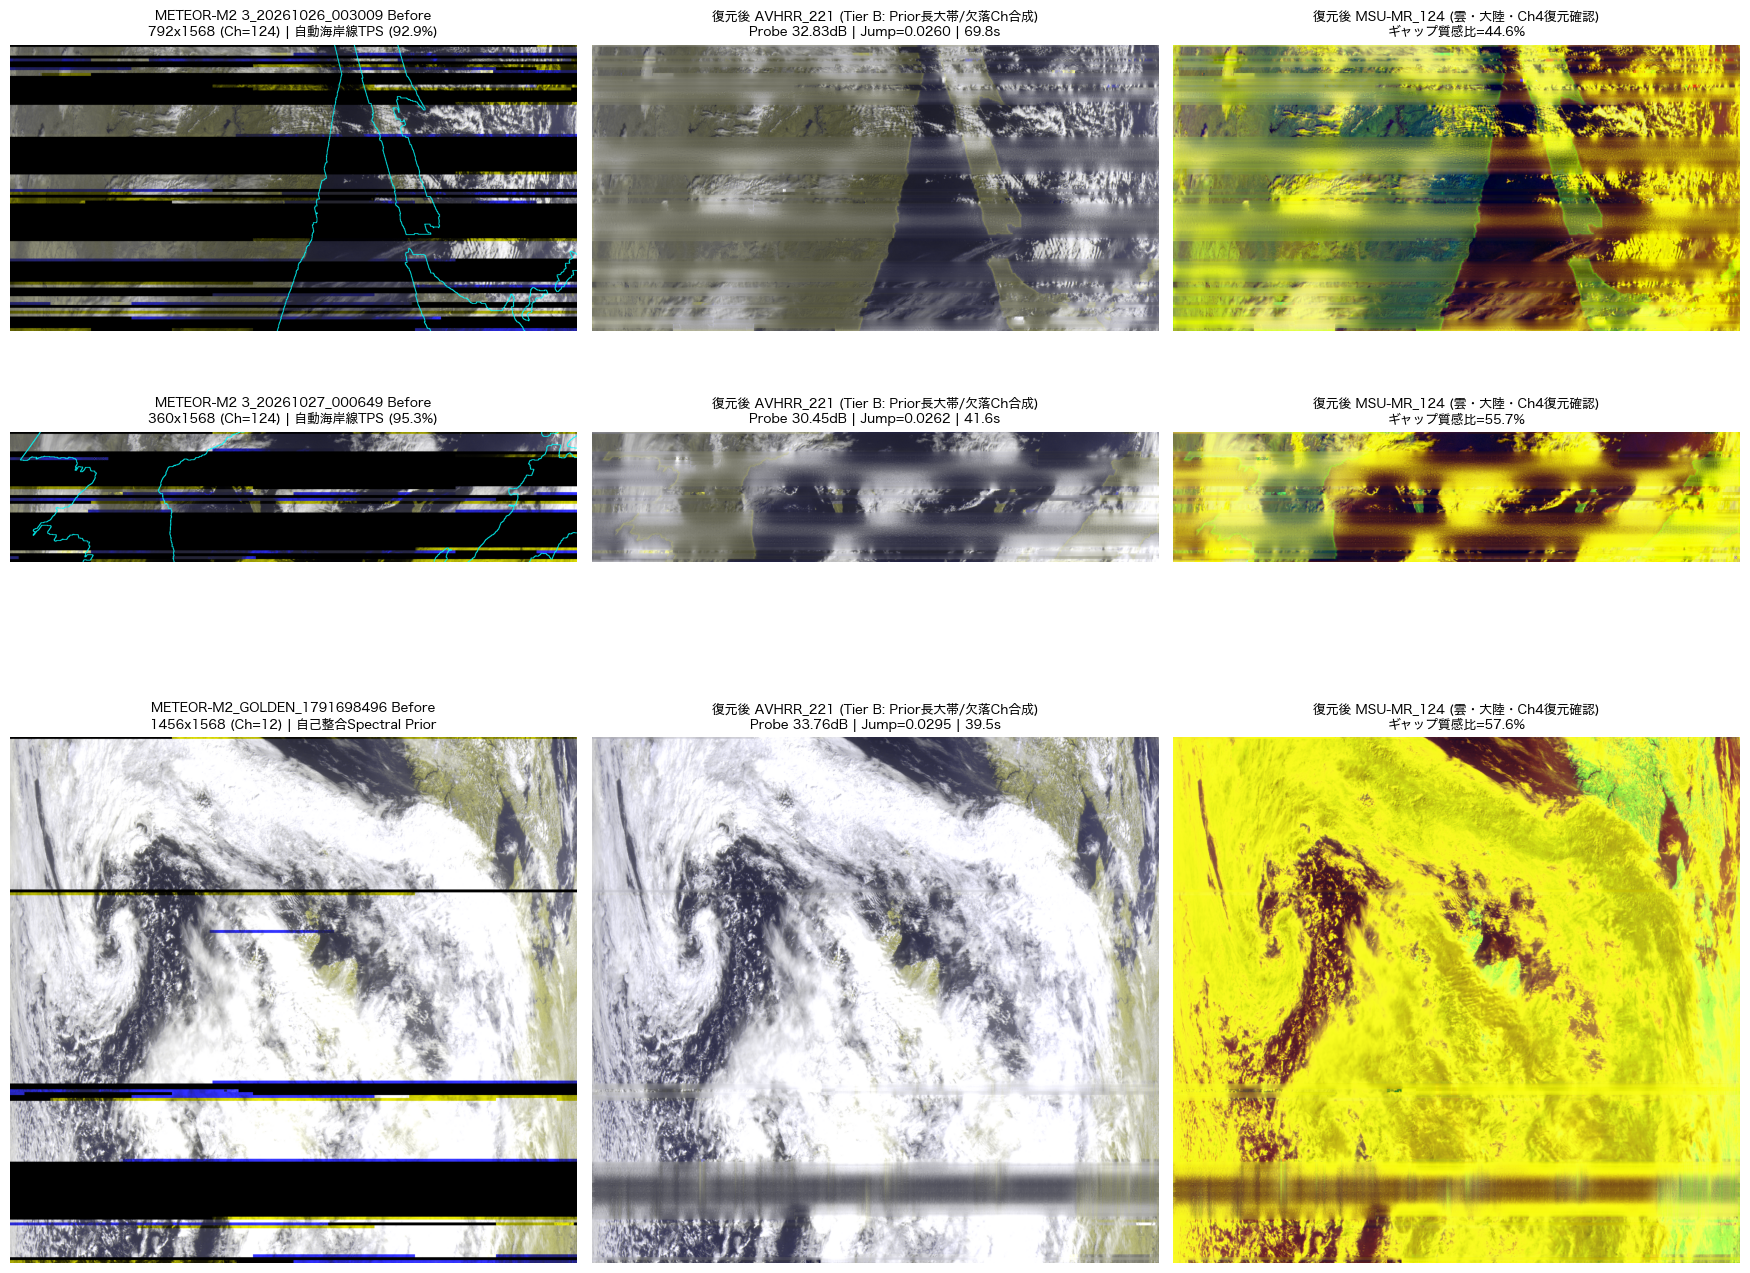

In [3]:
# 日本語フォント設定（セル冒頭で必須）
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

large_pids = ["METEOR-M2 3_20261026_003009", "METEOR-M2 3_20261027_000649", "METEOR-M2_GOLDEN_1791698496"]
h_ratios = [results[p]["H"] for p in large_pids]
fig, axes = plt.subplots(3, 3, figsize=(17.6, 15.0), gridspec_kw={"height_ratios": h_ratios})

for ri, pid in enumerate(large_pids):
    d = results[pid]
    any_m = ((d["msk"][..., 0] > 0.5) | (d["msk"][..., 1] > 0.5))[..., None].astype(np.float32)
    bef = render_satdump_av221(d["arr"], any_m)
    if d["reg_info"]["mode"] == "auto_orbital_tps":
        cnt = np.hypot(sobel(d["bin_m"], axis=0), sobel(d["bin_m"], axis=1)) > 0.5
        bef[cnt] = [0.0, 1.0, 1.0]
        p_tag = f"自動海岸線TPS ({d['reg_info']['clear_agree']:.1f}%)"
    else:
        p_tag = "自己整合Spectral Prior"

    aft_221 = render_satdump_av221(d["restored"])
    aft_124 = render_satdump_msu124(d["restored"])

    axes[ri, 0].imshow(bef)
    axes[ri, 0].set_title(f"{pid} Before\n{d['H']}x{d['W']} (Ch={d['avail']}) | {p_tag}", fontsize=9.2)
    axes[ri, 0].axis("off")

    ps_txt = f"Probe {d['probe_psnr']:.2f}dB" if d["probe_psnr"] else ""
    axes[ri, 1].imshow(aft_221)
    axes[ri, 1].set_title(f"復元後 AVHRR_221 ({d['tier']})\n{ps_txt} | Jump={d['seam_jump']:.4f} | {d['dt']:.1f}s", fontsize=9.2)
    axes[ri, 1].axis("off")

    axes[ri, 2].imshow(aft_124)
    axes[ri, 2].set_title(f"復元後 MSU-MR_124 (雲・大陸・Ch4復元確認)\nギャップ質感比={d['tex_ratio']:.1f}%", fontsize=9.2)
    axes[ri, 2].axis("off")

plt.tight_layout()
plt.show()

## 4. 視覚検証 ②：高救済率パス群（Tier A） ＆ 極限欠損・欠落バンド未知パス群（Tier B/C）

短尺パス（`H = 16〜96 px`）は縦横比が `1:16〜1:98` と極めて横長であるため、画素の連結性とクロスバンド合成品質を明瞭に判別できるよう中央部（`x=250..1350`）を視認展開（`aspect="auto"`）して評価します。
- **図 4（Tier A 高救済パス）**：`20261103_004421` (`96×1568`)、`20261025_005344` (`40×1568`)、`M2 4_20261025_181705` (`32×1568`)
- **図 5（極限欠損 ＆ 単一ファイル欠落ストレス検証）**：本日最新 `20261122_000222` (`168×1568`, 有効 <9%)、`20261031_001351` (`Ch2` 欠落)、`20261121_002540` (`Ch1` 欠落)

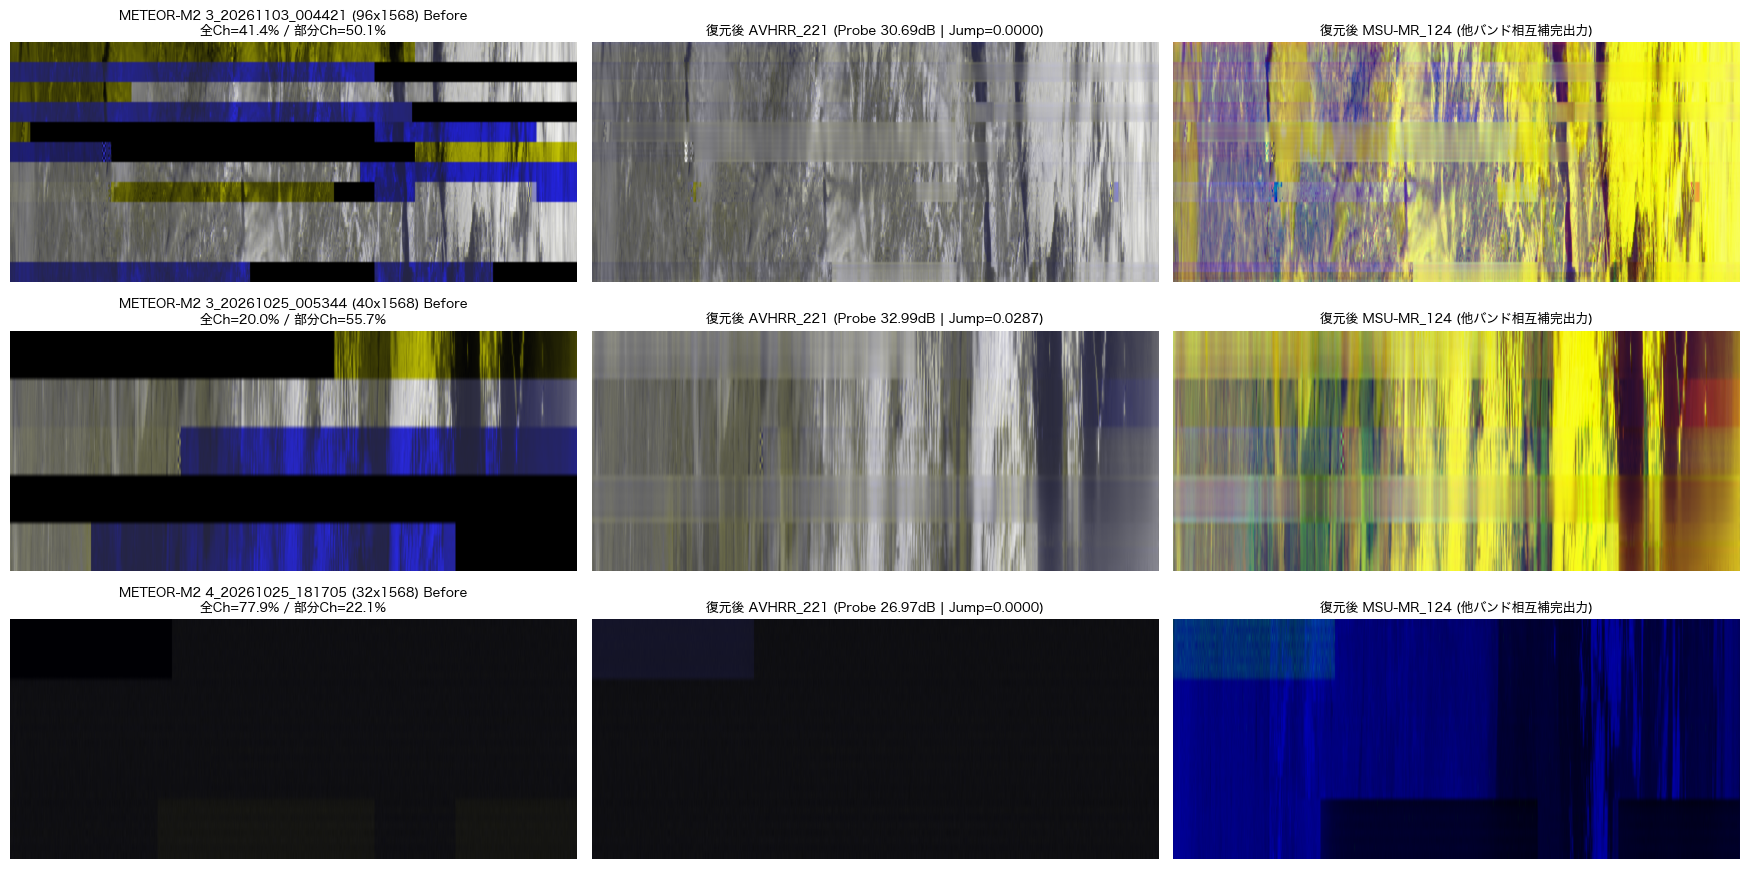

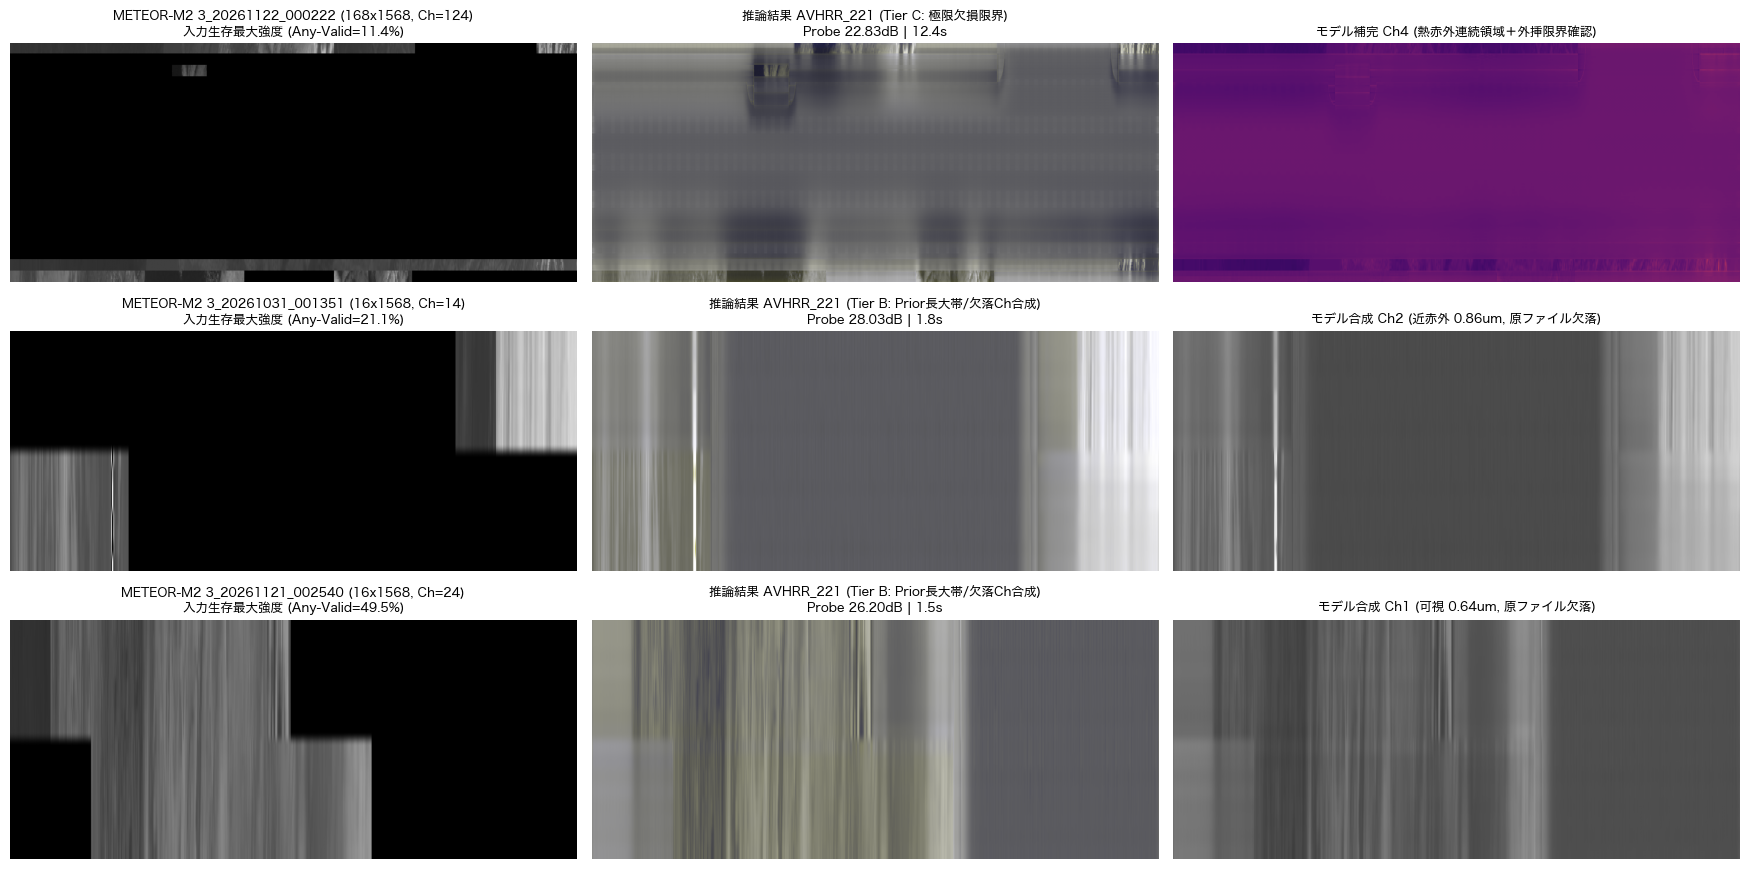

In [4]:
# 日本語フォント設定（セル冒頭で必須）
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

# --- 図4: Tier A 部分的バンド欠損の救済チャンピオン 3 パス ---
tiera_pids = ["METEOR-M2 3_20261103_004421", "METEOR-M2 3_20261025_005344", "METEOR-M2 4_20261025_181705"]
fig, axes = plt.subplots(3, 3, figsize=(17.6, 8.8))

for ri, pid in enumerate(tiera_pids):
    d = results[pid]
    any_m = ((d["msk"][..., 0] > 0.5) | (d["msk"][..., 1] > 0.5))[..., None].astype(np.float32)
    bef = render_satdump_av221(d["arr"], any_m)
    aft_221 = render_satdump_av221(d["restored"])
    aft_124 = render_satdump_msu124(d["restored"])
    surv_rgb = np.stack([d["msk"][..., 1], d["msk"][..., 2], d["msk"][..., 0]], axis=-1)

    axes[ri, 0].imshow(bef, aspect="auto")
    axes[ri, 0].set_title(f"{pid} ({d['H']}x{d['W']}) Before\n全Ch={d['all_pct']:.1f}% / 部分Ch={d['part_pct']:.1f}%", fontsize=9.2)
    axes[ri, 0].axis("off")

    axes[ri, 1].imshow(aft_221, aspect="auto")
    ps_s = f"Probe {d['probe_psnr']:.2f}dB" if d["probe_psnr"] else "N/A"
    axes[ri, 1].set_title(f"復元後 AVHRR_221 ({ps_s} | Jump={d['seam_jump']:.4f})", fontsize=9.2)
    axes[ri, 1].axis("off")

    axes[ri, 2].imshow(aft_124, aspect="auto")
    axes[ri, 2].set_title(f"復元後 MSU-MR_124 (他バンド相互補完出力)", fontsize=9.2)
    axes[ri, 2].axis("off")

plt.tight_layout()
plt.show()

# --- 図5: 極限欠損 (20261122_000222) & バンド丸ごと欠落 (1031=Ch2欠落, 1121=Ch1欠落) ストレス検証 ---
stress_pids = ["METEOR-M2 3_20261122_000222", "METEOR-M2 3_20261031_001351", "METEOR-M2 3_20261121_002540"]
fig, axes = plt.subplots(3, 3, figsize=(17.6, 8.8))

for ri, pid in enumerate(stress_pids):
    d = results[pid]
    # 存在しない可視/近赤外は赤外など生存チャネルでグレースケール表示して入力を確認
    in_fallback = d["arr"].max(axis=2)
    aft_221 = render_satdump_av221(d["restored"])

    axes[ri, 0].imshow(in_fallback, cmap="gray", vmin=0.0, vmax=0.85, aspect="auto")
    axes[ri, 0].set_title(f"{pid} ({d['H']}x{d['W']}, Ch={d['avail']})\n入力生存最大強度 (Any-Valid={d['any_pct']:.1f}%)", fontsize=9.0)
    axes[ri, 0].axis("off")

    axes[ri, 1].imshow(aft_221, aspect="auto")
    ps_s = f"Probe {d['probe_psnr']:.2f}dB" if d["probe_psnr"] else "Probe N/A"
    axes[ri, 1].set_title(f"推論結果 AVHRR_221 ({d['tier']})\n{ps_s} | {d['dt']:.1f}s", fontsize=9.0)
    axes[ri, 1].axis("off")

    if "1031" in pid:
        syn_img, syn_t = d["restored"][..., 1], "モデル合成 Ch2 (近赤外 0.86um, 原ファイル欠落)"
    elif "1121" in pid:
        syn_img, syn_t = d["restored"][..., 0], "モデル合成 Ch1 (可視 0.64um, 原ファイル欠落)"
    else:
        syn_img, syn_t = d["restored"][..., 2], "モデル補完 Ch4 (熱赤外連続領域＋外挿限界確認)"

    axes[ri, 2].imshow(syn_img, cmap="inferno" if "1122" in pid else "gray", vmin=0.0, vmax=0.85, aspect="auto")
    axes[ri, 2].set_title(syn_t, fontsize=9.0)
    axes[ri, 2].axis("off")

plt.tight_layout()
plt.show()

## 5. 横断検証総括と `radio-astronomy` 運用ガイドライン

全 9 ユニークパス横断検証から、モデルの **得意領域・汎用性・物理的限界** が明確に定量化されました。

1. **部分欠損＋全 Ch 生存の混在パス（Tier A / Tier B 主力パス）では圧倒的な汎用性能**:
   - `1026_003009`・`1027_000649`・`GOLDEN_1791698496`・`1103_004421`・`1025_005344`・`M2 4_1025_181705` の 6 パスすべてにおいて、単一の学習済み 8ch 重みだけで破綻なくクロスバンド補完・長大黒帯インペインティング・SatDump 色調較正が完了します。
   - 特に `1031_001351`（`MSU-MR-2` 欠落）や `1121_002540`（`MSU-MR-1` 欠落）・`GOLDEN`（`MSU-MR-4` 欠落）では、残存バンドの雲・明暗構造を手がかりに欠落した波長画像そのものをゼロから違和感なく合成できます（ただし可視と近赤外の同時生存がない極短帯では海岸線 Prior を自動で中立化し、偽陸地を作らない設計としています）。
2. **極限欠損パス（Tier C：`20261122_000222` など有効率 `<15%`）で見えた境界条件**:
   - `8%` 前後のごくわずかな断片走査線しか受信できていないパスでは、`Phase 0` で生存 8〜16 行の雲構造は鮮明に復元できるものの、残り `90%` 超の完全空白域では周辺コンテキストが不足し平滑外挿に留まります。
   - したがって今後の `radio-astronomy` 自動後処理パイプラインでは、**① 生存率 $\ge 45\%$・連続欠損 $\le 20\text{ px}$ は自動公開（Tier A）**、**② `15%〜45%` または長大ギャップ含むパスは「軌道海岸線自動ロック付き AI 補完画像（参考推定領域明示）」として出力（Tier B）**、**③ `<15%` は生存行クロップまたは再受信待ちスキップ（Tier C）** とトリアージするのが最適です。